# Debug de separación de una mezcla

Ejecutar las celdas en orden. Se procesa **una mezcla** y se registran todas las imágenes intermedias del código real: entradas, decoder, máscaras, saturación, capas y estimaciones. Cada cambio de un tensor queda guardado en `trace.records`; las imágenes idénticas de una misma variable dentro de una llamada se muestran una sola vez.

`Crop3TestLayered` corrige una frontera por fuente en cada iteración externa de `decode`, conservando la resta acumulada entre iteraciones. El registro requiere ejecución eager y agrega tiempo de ejecución. No ejecuta optimización ni guarda resultados automáticamente.


In [2]:
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from IPython.display import display

project_root = next(
    root for root in (Path.cwd(), *Path.cwd().parents)
    if (root / "project" / "CROP" / "models").is_dir()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from project.loader import Loader
import project.CROP.models.crop3 as crop3_module
import project.CROP.models.crop3_test as crop3_test_module
import project.CROP.models.crop3_test_layered as layered_module
import project.experiments.debug.trace_images as trace_module

for module in (crop3_module, crop3_test_module, layered_module, trace_module):
    importlib.reload(module)

MODELS = {

    "Crop3TestLayered": layered_module.Crop3TestLayered,
}

MODEL = "Crop3TestLayered"
DATASET = "fashion"
CVAE_NAME = "int_256_lat_64_beta_0_4_fashion.keras"
PREDICTOR_NAME = f"CCE_Conv2D_{DATASET}.keras"
IMAGE_INDEX = 0
ITERATIONS = 5
SEED = 3333
IMAGE_SHAPE = (28, 28)
PARAMS = {
    "alpha_1": -2,
    "alpha_2": -22,
    "bias": 0.22,
    "slope": 22,
    "beta": 1.0,
    "alpha_mix": 0.5,
    "gamma": 1.2722776210672107,
    "delta": 0.353,
    "saturation_object_threshold": 0.05,
}


2026-11-06 19:44:18.984882: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Usando fashion como dataset


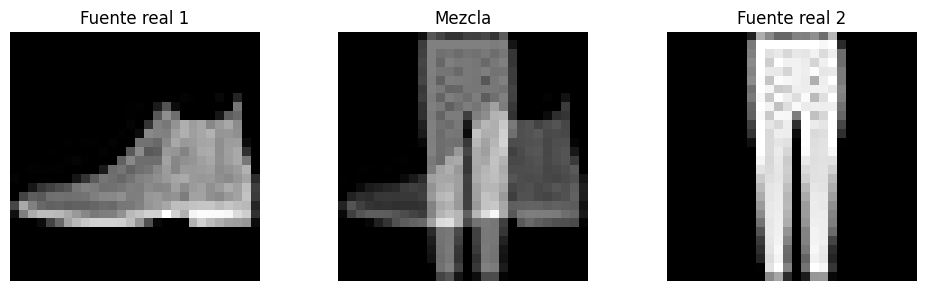

In [3]:
tf.keras.utils.set_random_seed(SEED)
cvae = Loader.cvae(model_name=CVAE_NAME)
predictor = Loader.predictor(model_name=PREDICTOR_NAME)
data = Loader.data(dataset=DATASET)
assert 0 <= IMAGE_INDEX < min(len(data["x_test"]), len(data["x_test_1"]))
assert ITERATIONS > 0

source1 = data["x_test"][IMAGE_INDEX:IMAGE_INDEX + 1]
source2 = data["x_test_1"][IMAGE_INDEX:IMAGE_INDEX + 1]
model = MODELS[MODEL](cvae=cvae, predictor=predictor)
model.model_params = {**model.default_params, **PARAMS}
model.mix(source1, source2, model.model_params)

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, title, value in zip(axes, ["Fuente real 1", "Mezcla", "Fuente real 2"],
                            [source1, model.mixed_input, source2]):
    ax.imshow(np.asarray(value).reshape(IMAGE_SHAPE), cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


In [4]:
# Ejecuta exactamente decode() del modelo elegido: no replica sus formulas.
trace = trace_module.ImageTrace(model, IMAGE_SHAPE)
estimates = []
with trace:
    for iteration in range(ITERATIONS):
        model.iteration = iteration
        model.decode()
        estimates.append((
            np.asarray(model.source1_estimation).reshape(IMAGE_SHAPE).copy(),
            np.asarray(model.source2_estimation).reshape(IMAGE_SHAPE).copy(),
        ))
print(f"{MODEL}: {ITERATIONS} iteraciones; {len(trace.records)} imágenes registradas.")


Crop3TestLayered: 5 iteraciones; 498 imágenes registradas.


## Todas las imágenes intermedias

Se muestran todas por defecto, en orden de ejecución. Para inspeccionar una parte, ajustar los filtros. Cada título indica la función, el nombre de la variable y la línea donde se capturó su valor (al entrar en esa línea, después de ejecutar la anterior).

Los valores fuera de `[0, 1]` usan una escala que incluye todo su rango y una barra de color. Así se puede distinguir la saturación del blanco de valor 1. Las máscaras booleanas usan 0 y 1. `layer` identifica la frontera corregida en esa llamada; `return` muestra la imagen devuelta por una función.


Iteración 1: 90 imágenes


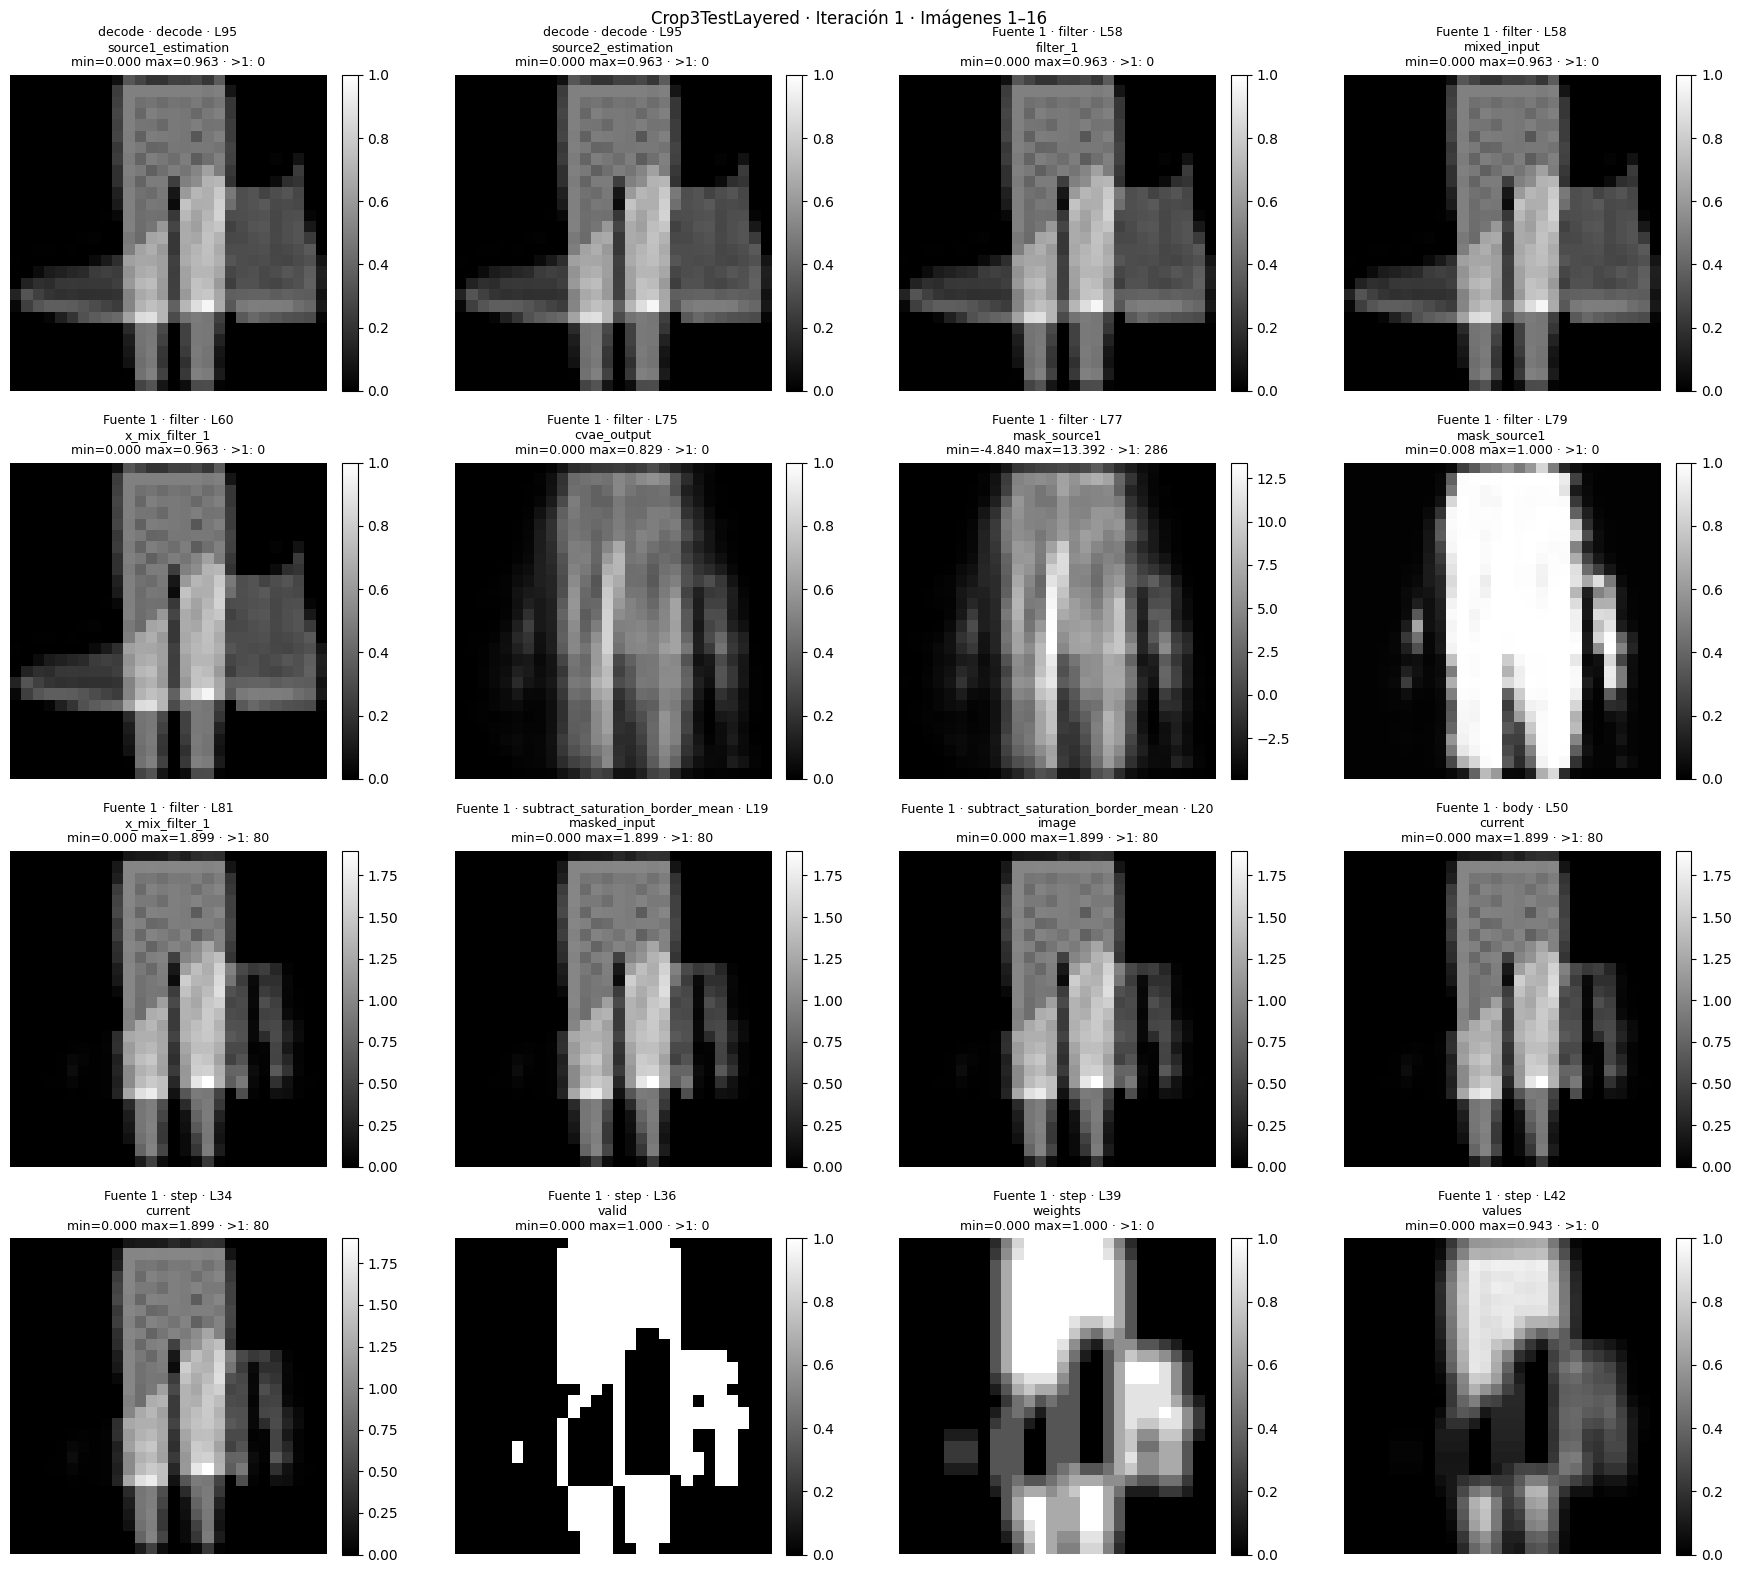

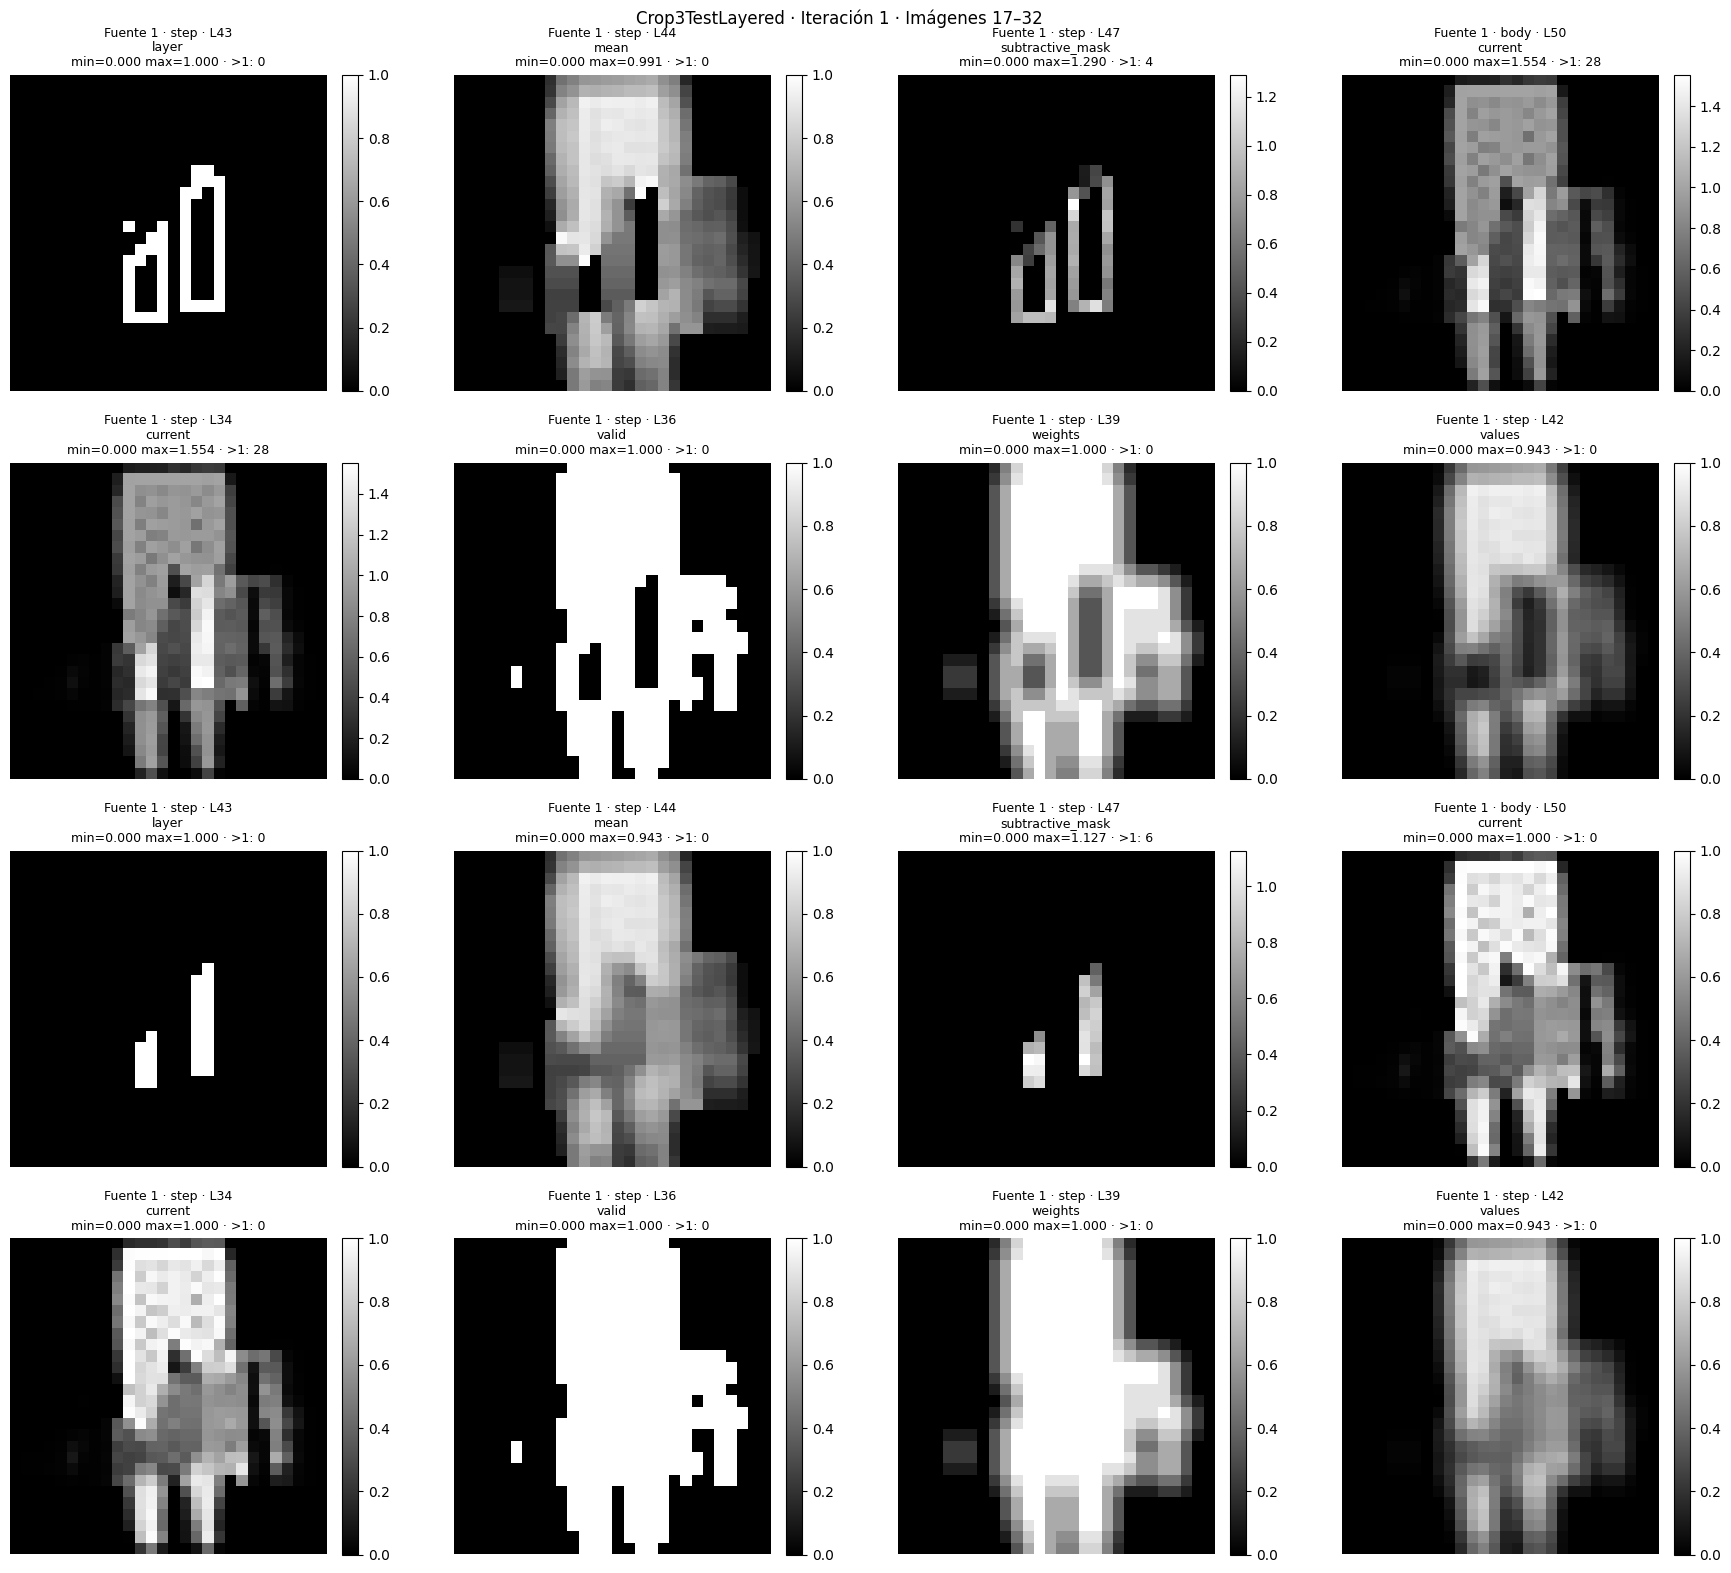

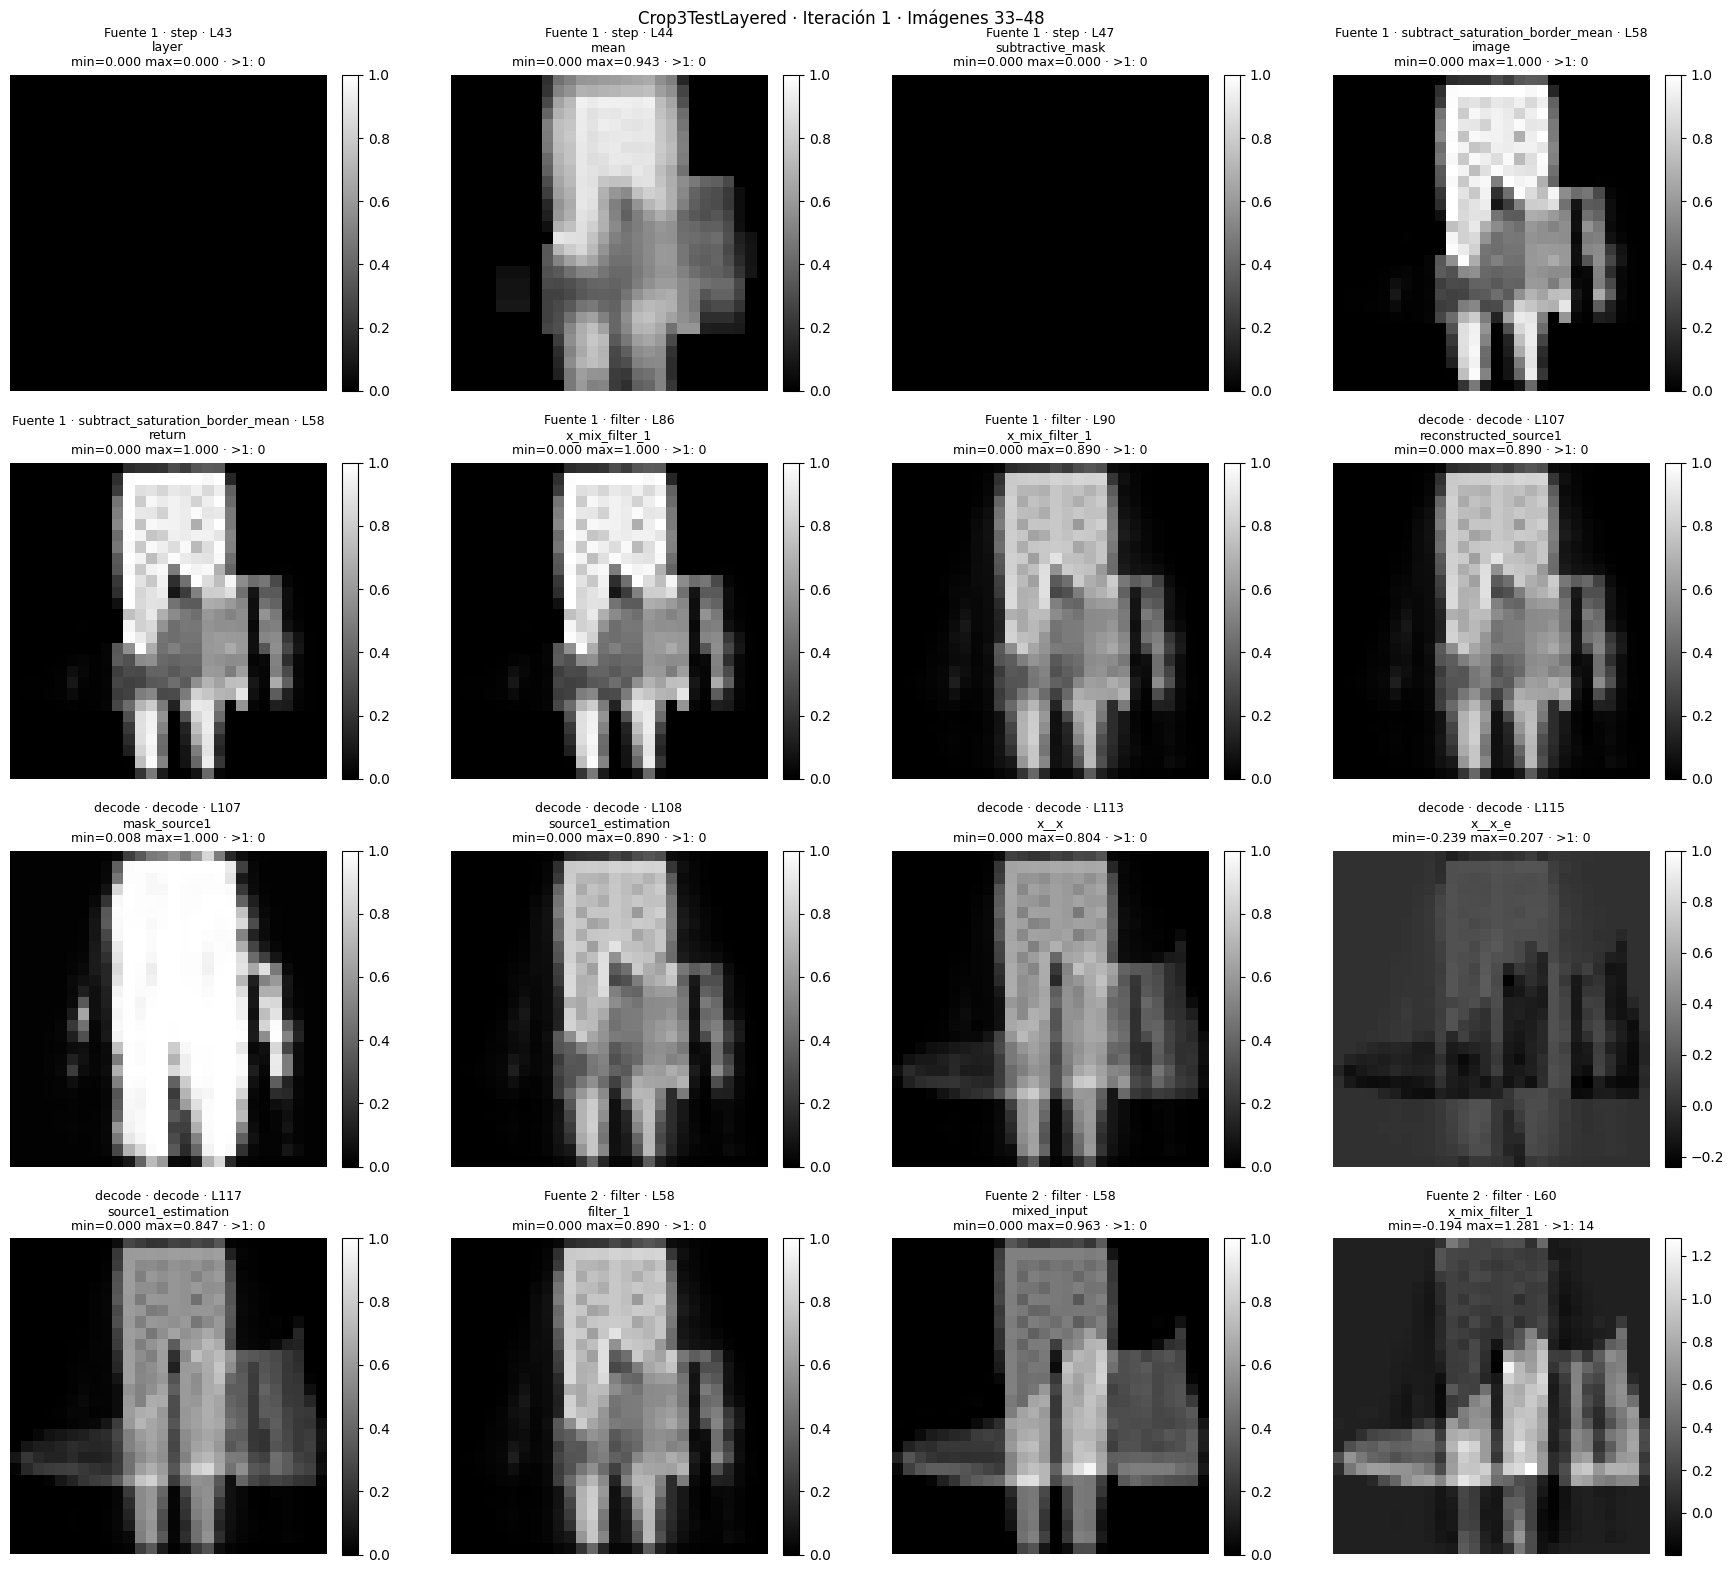

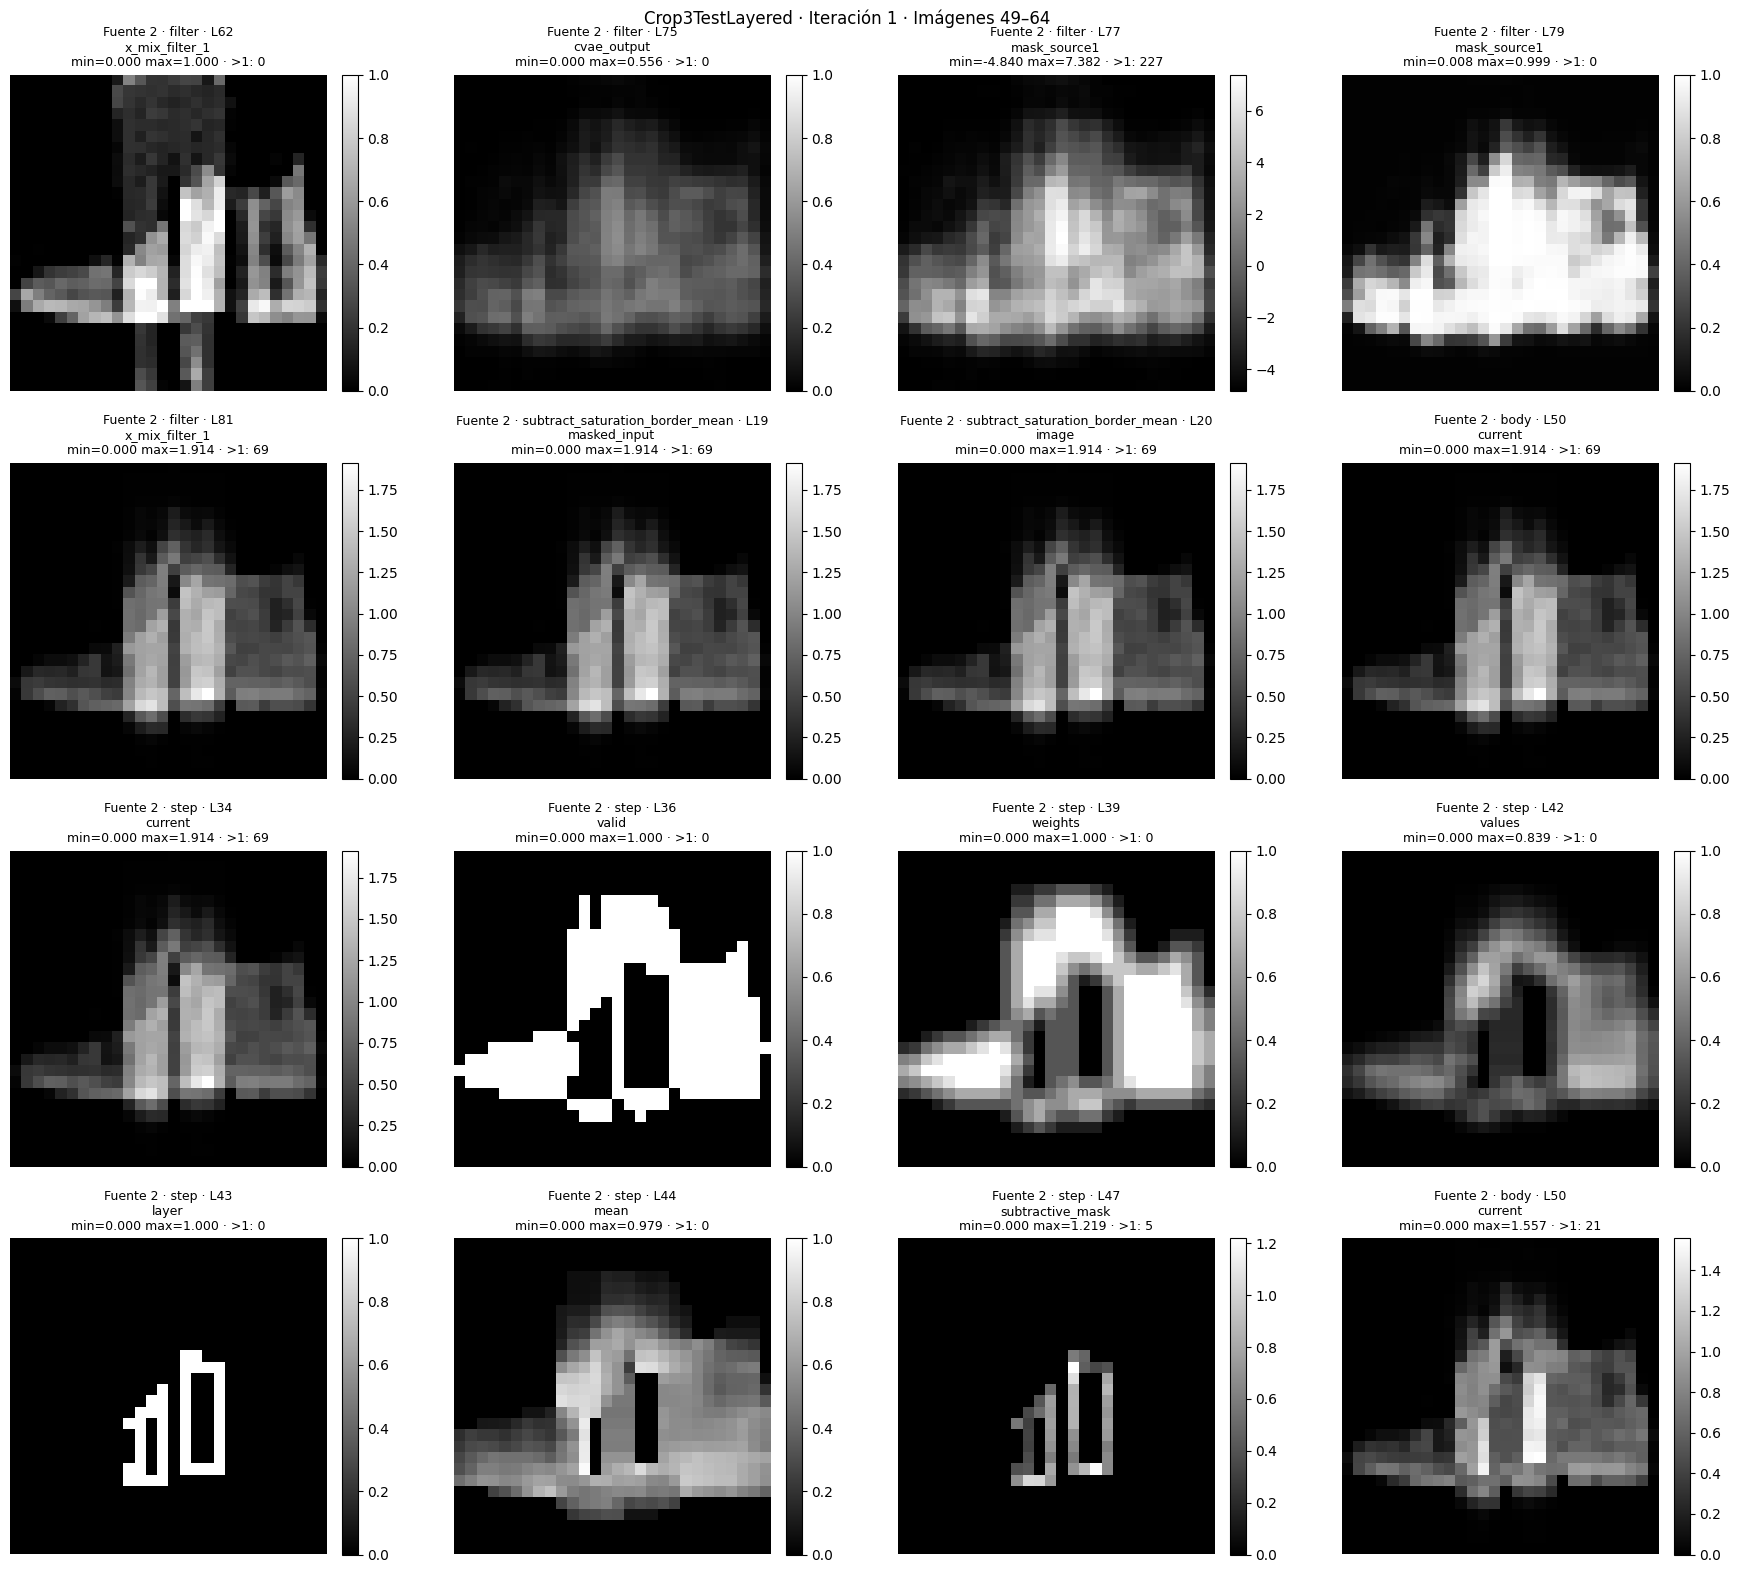

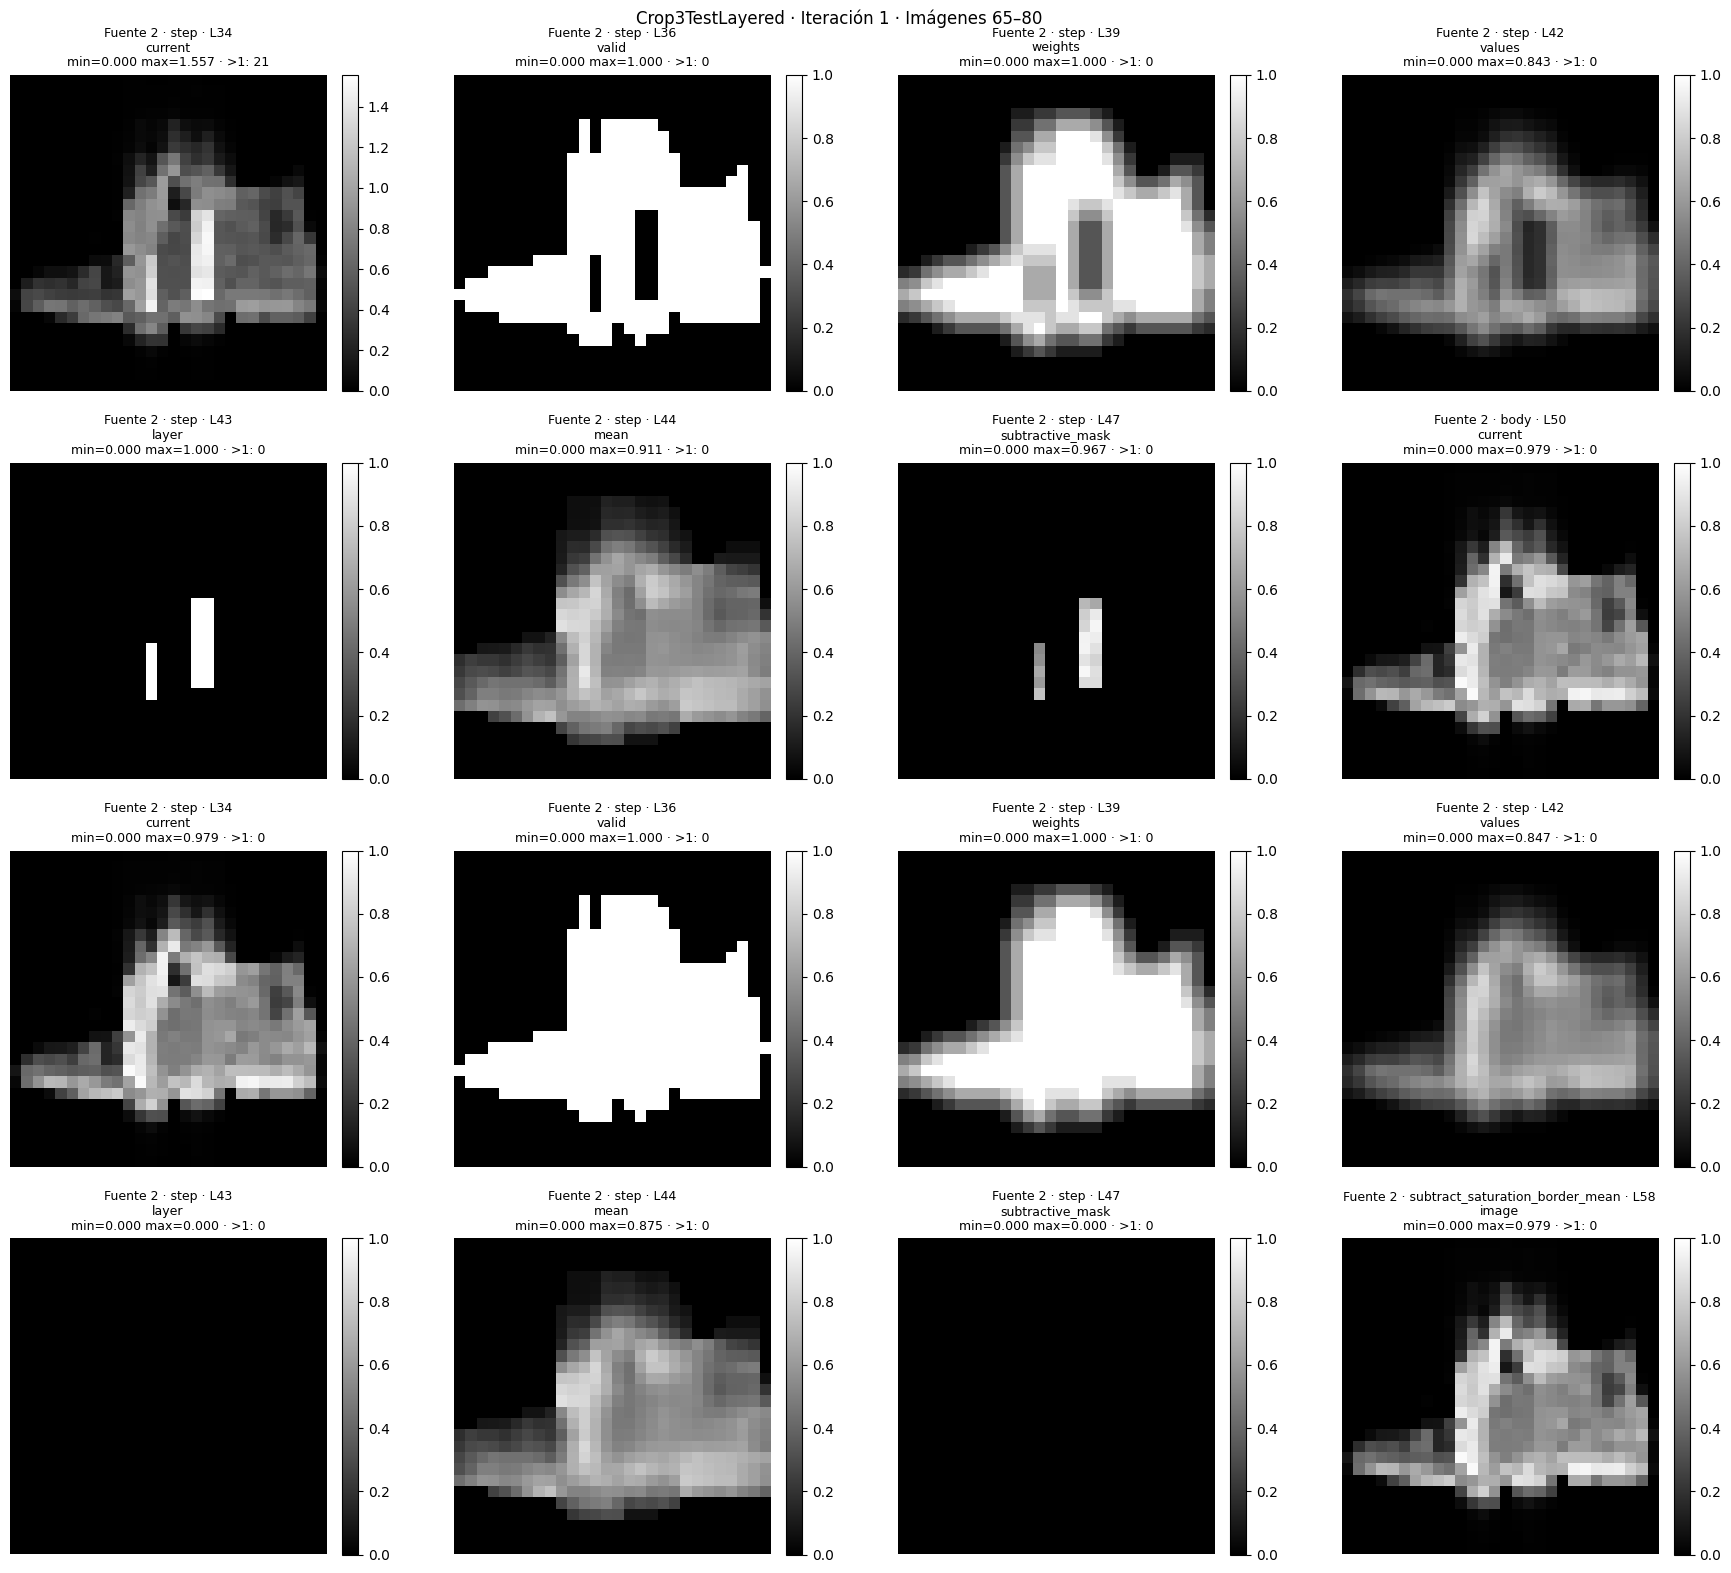

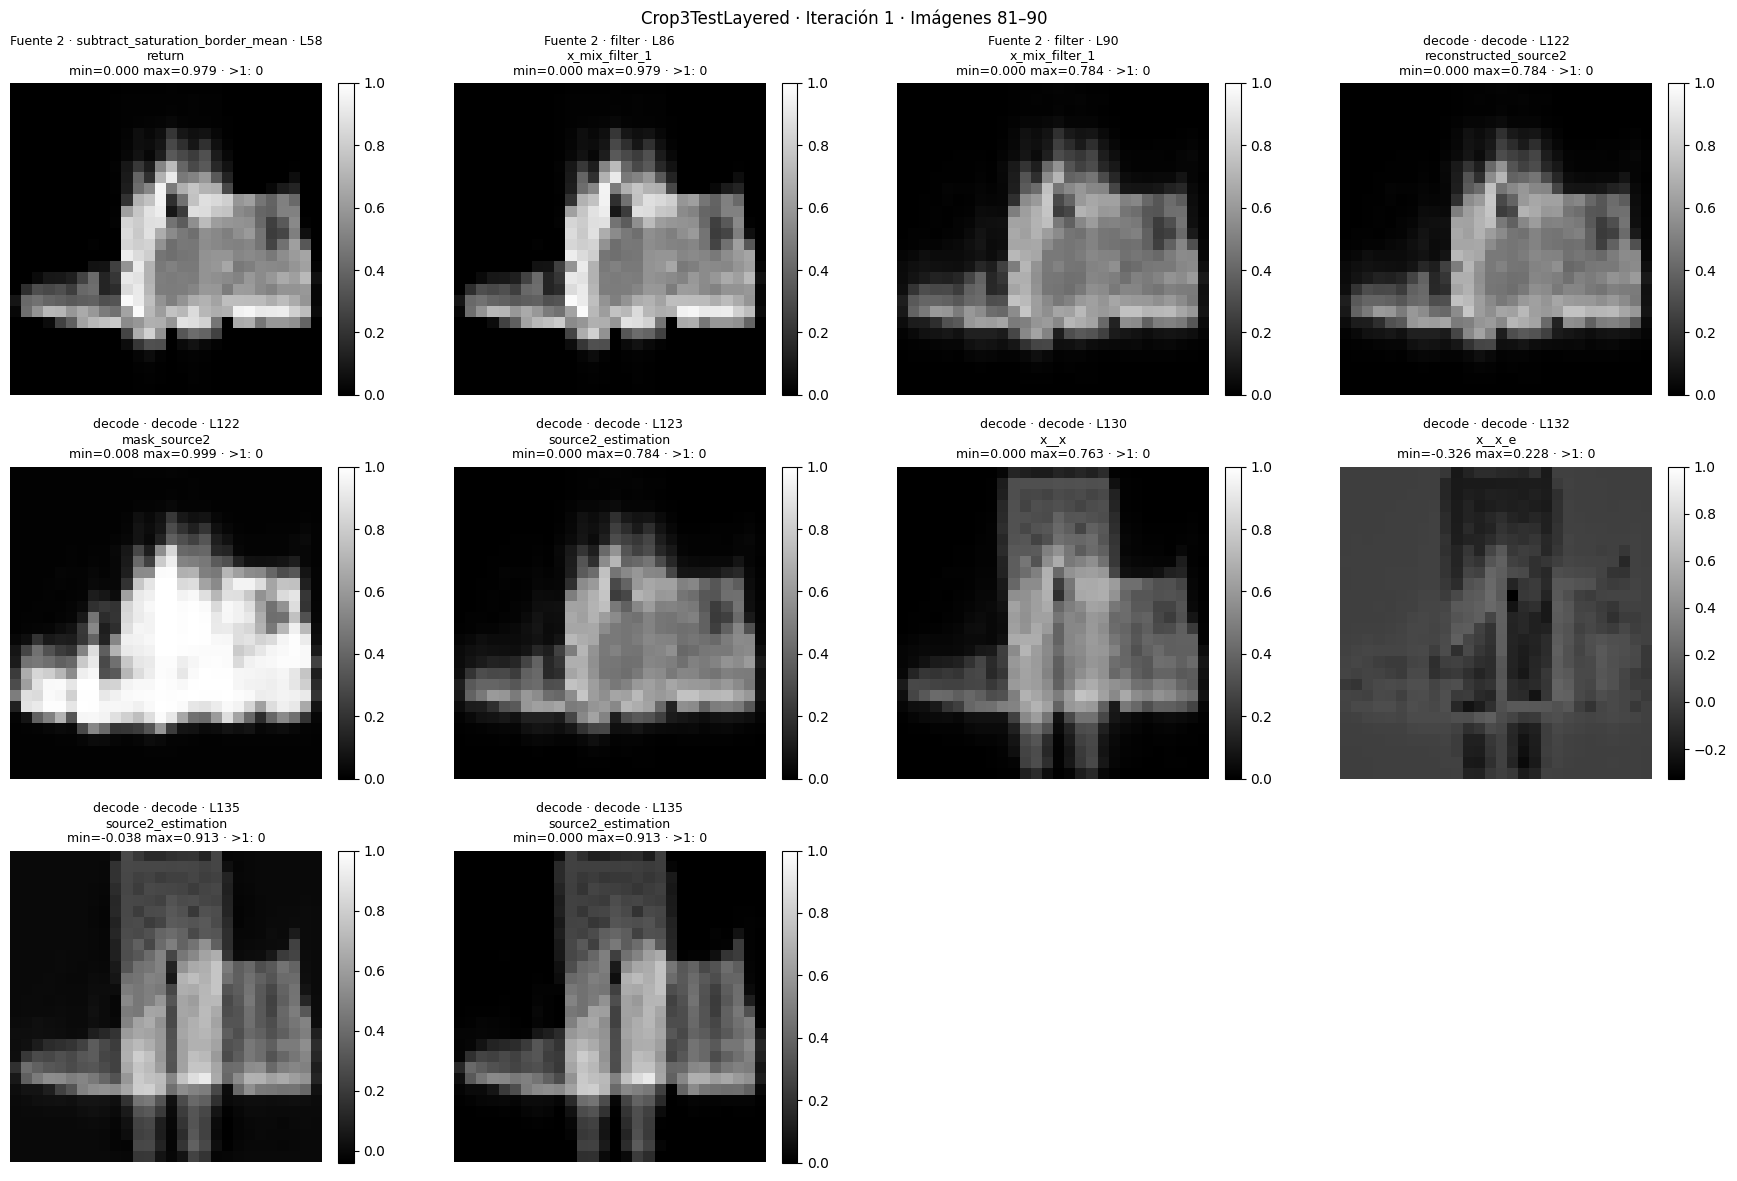

Iteración 2: 92 imágenes


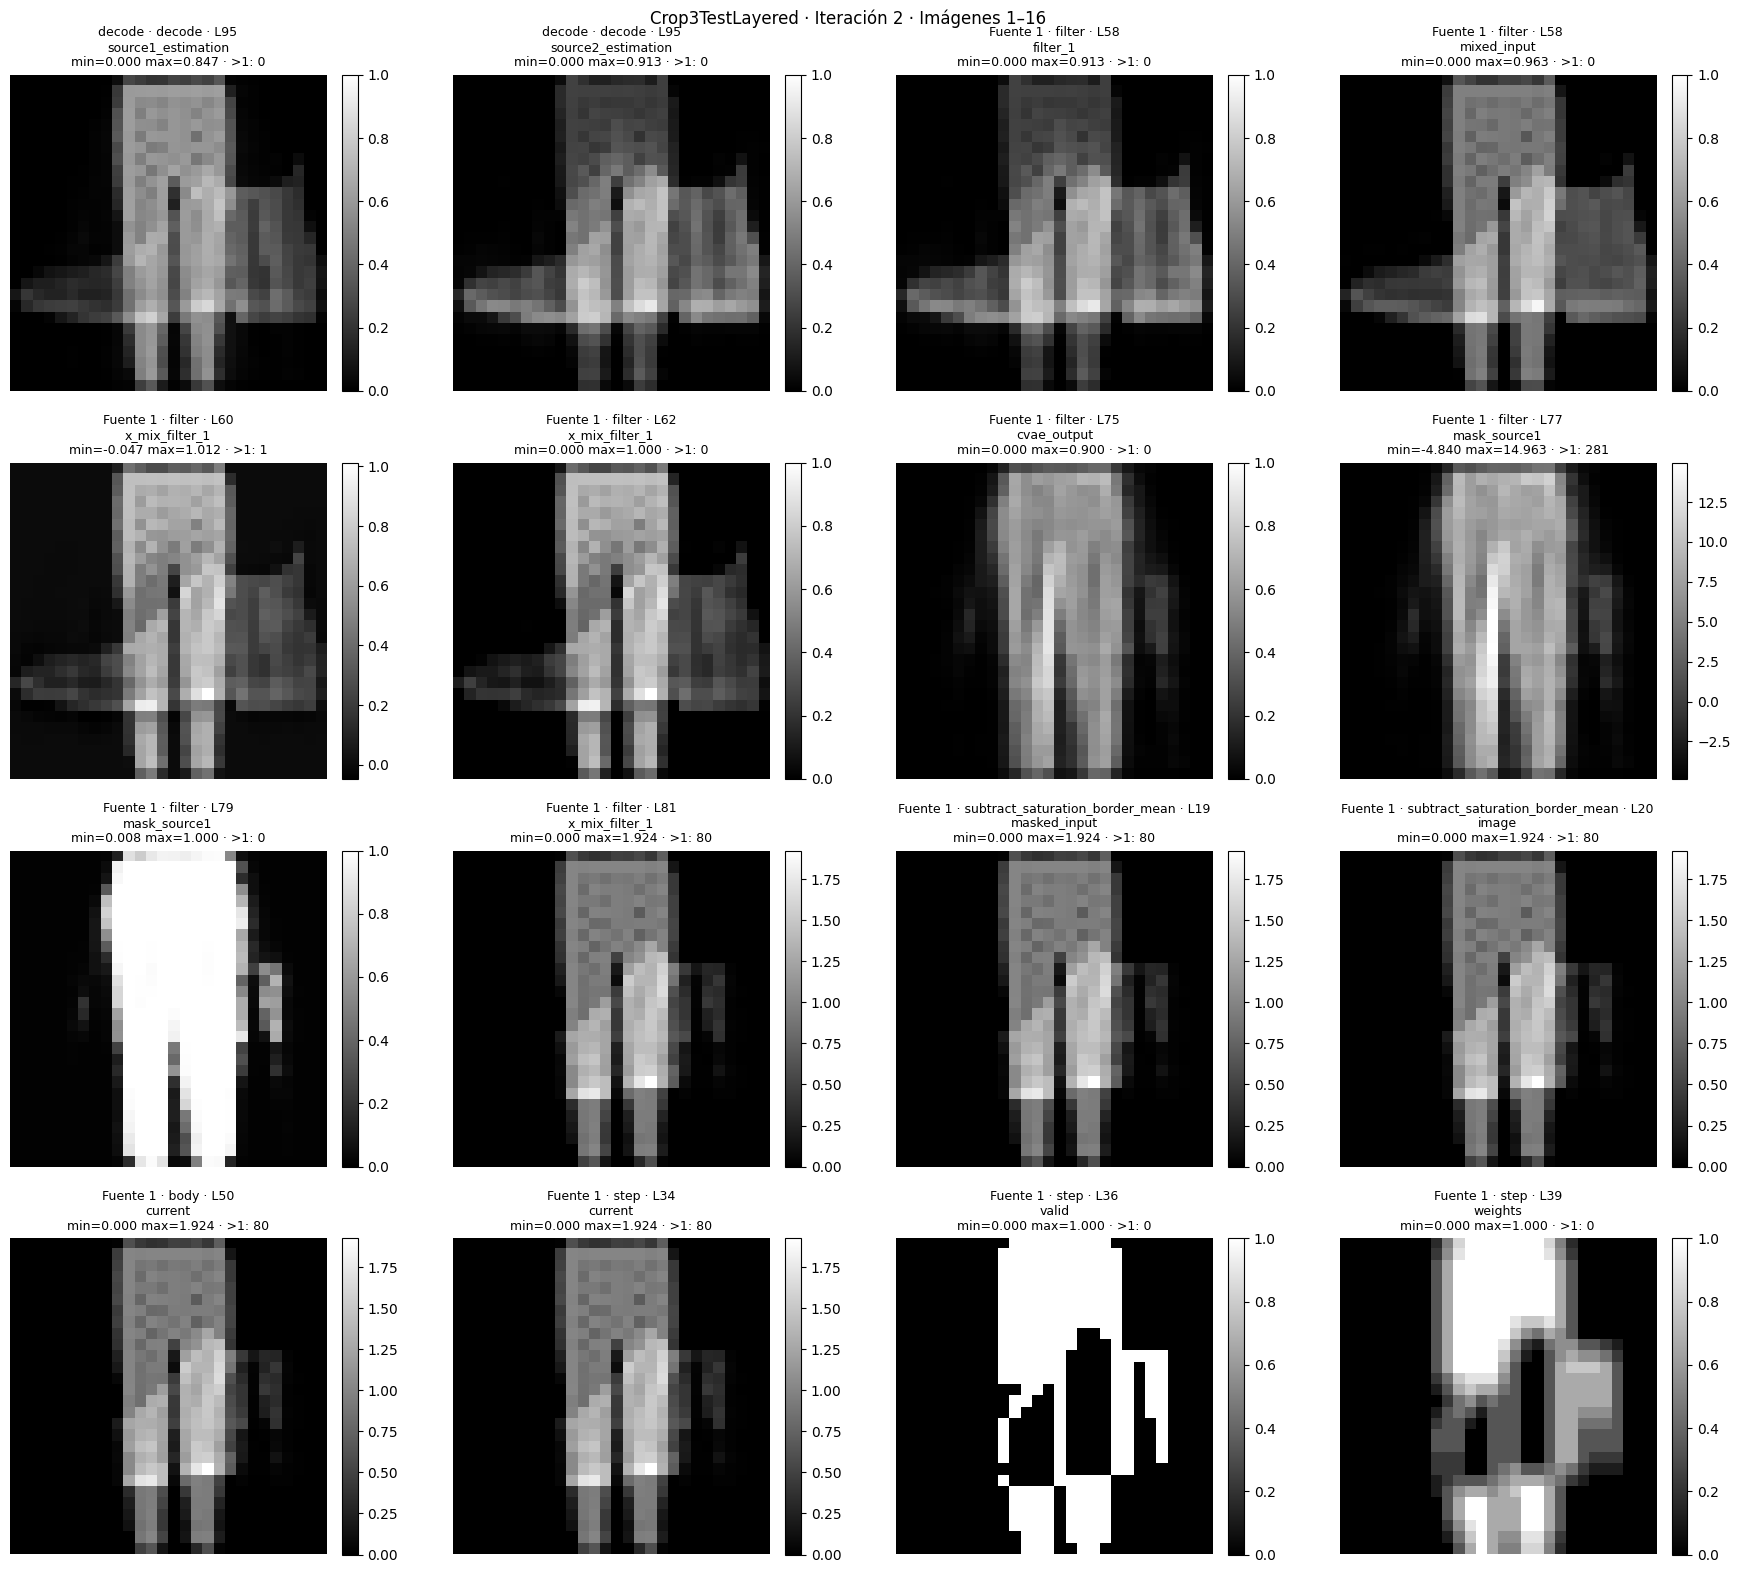

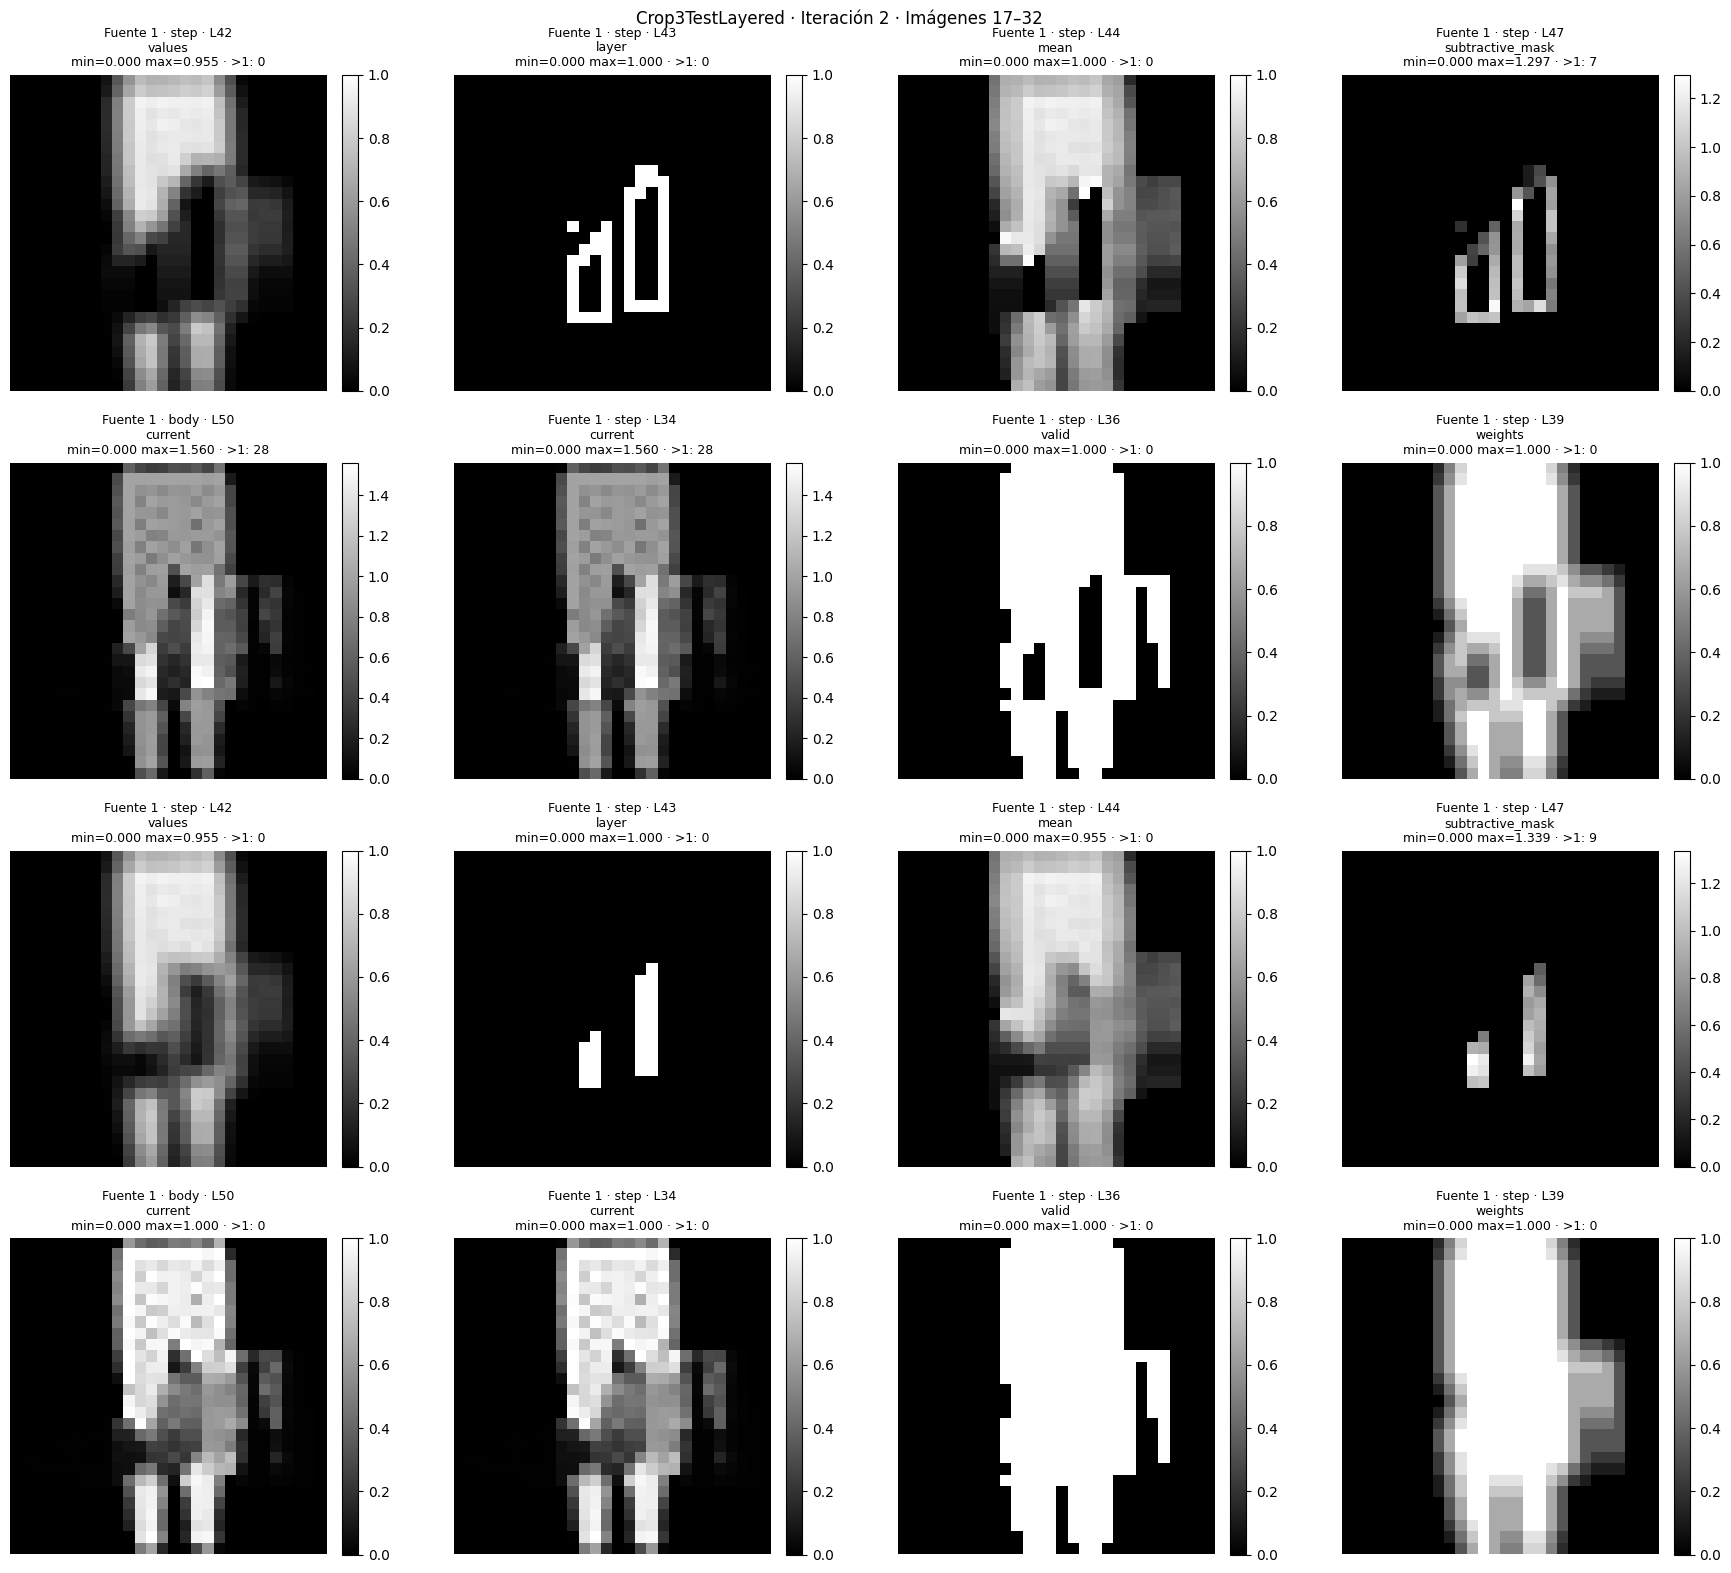

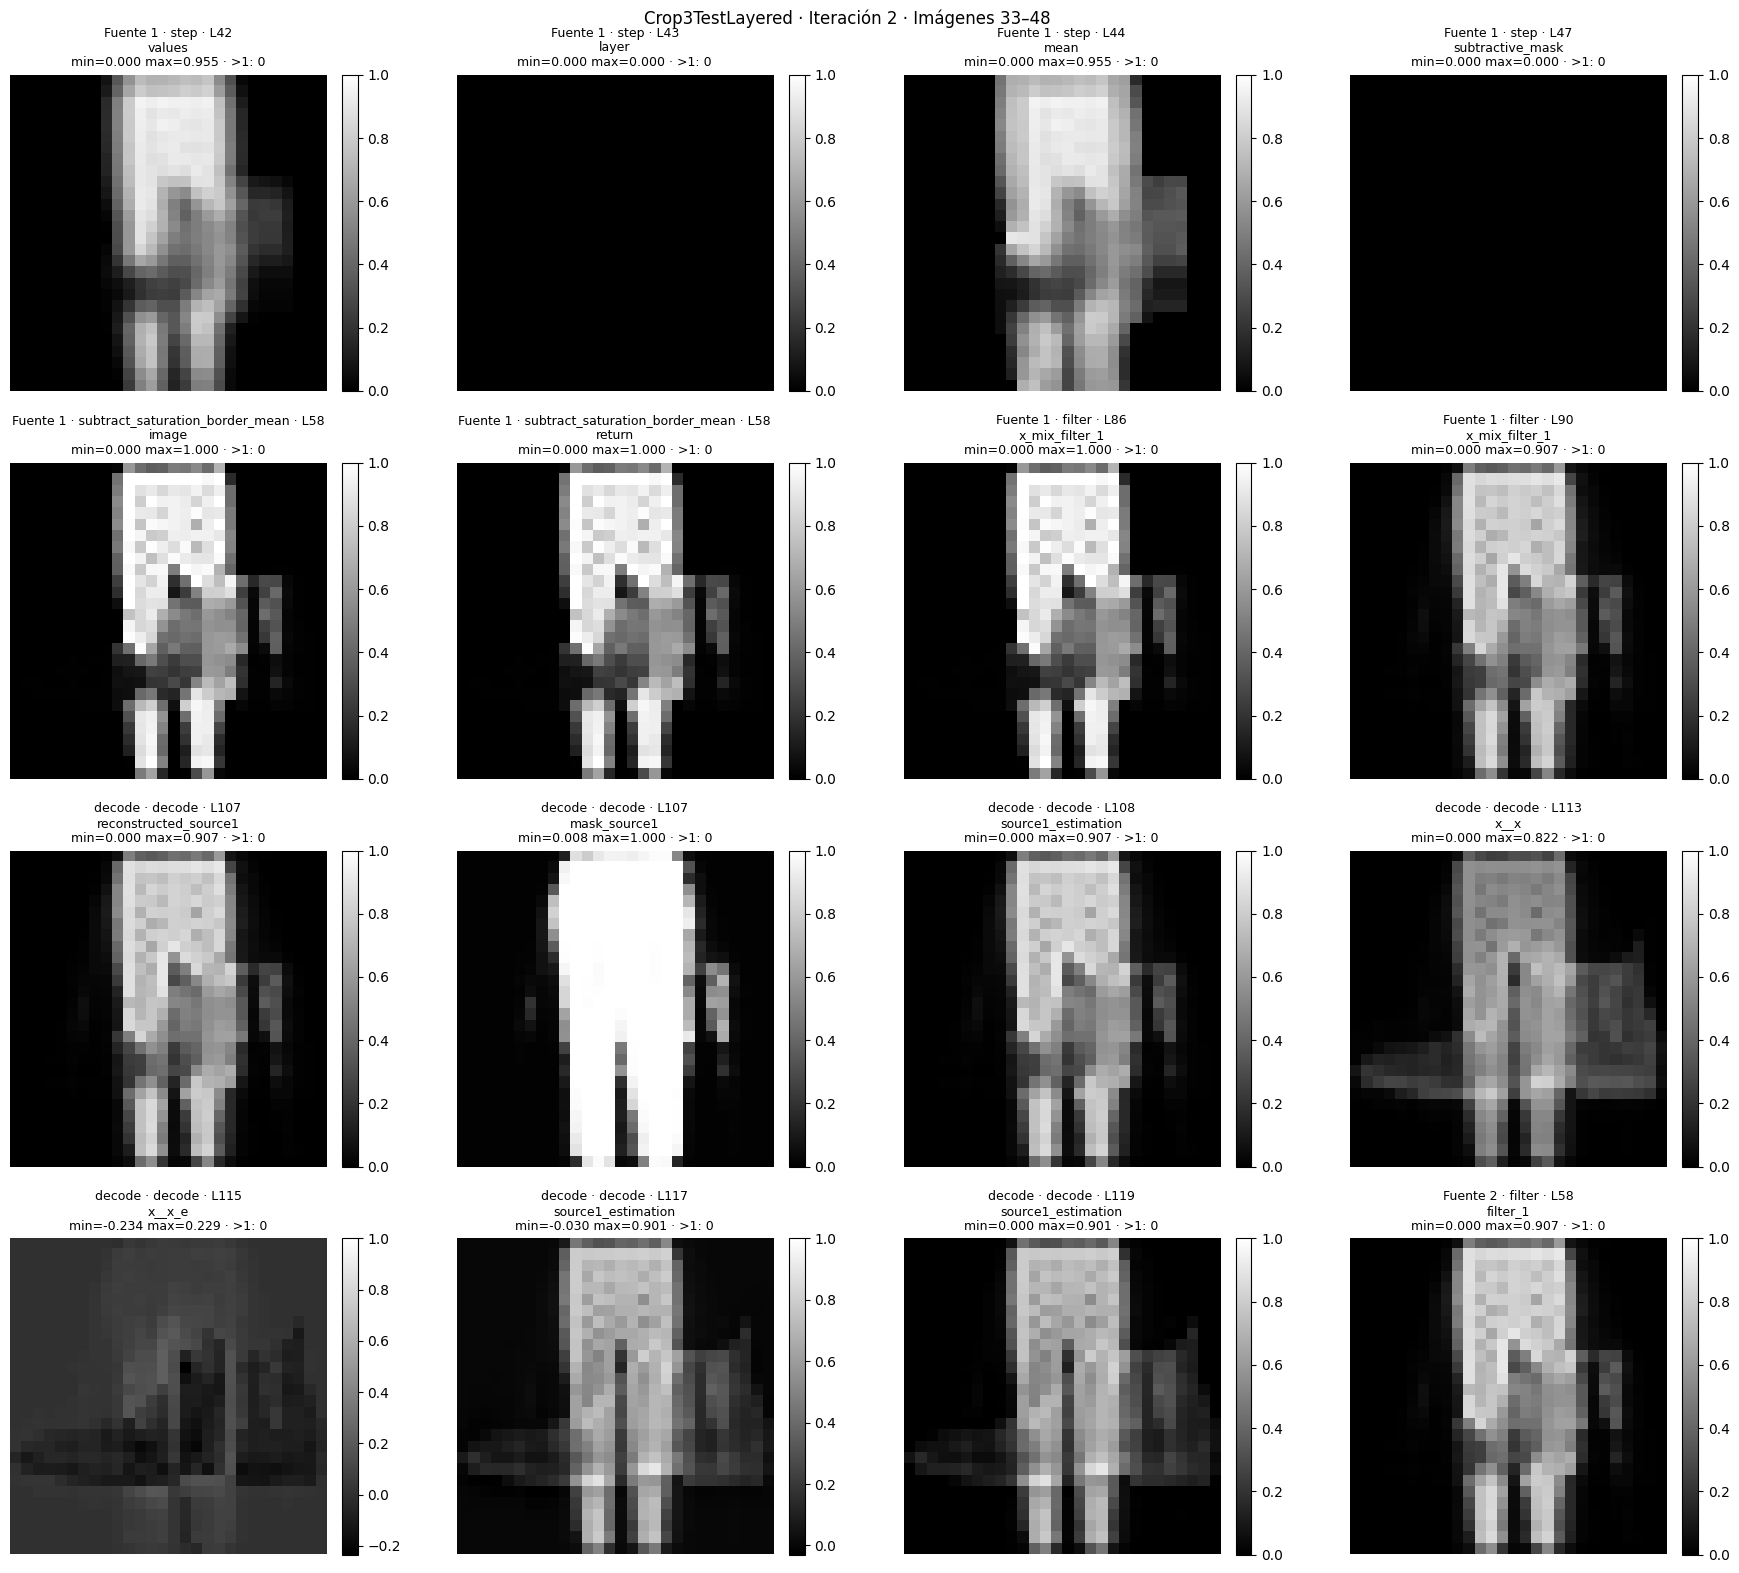

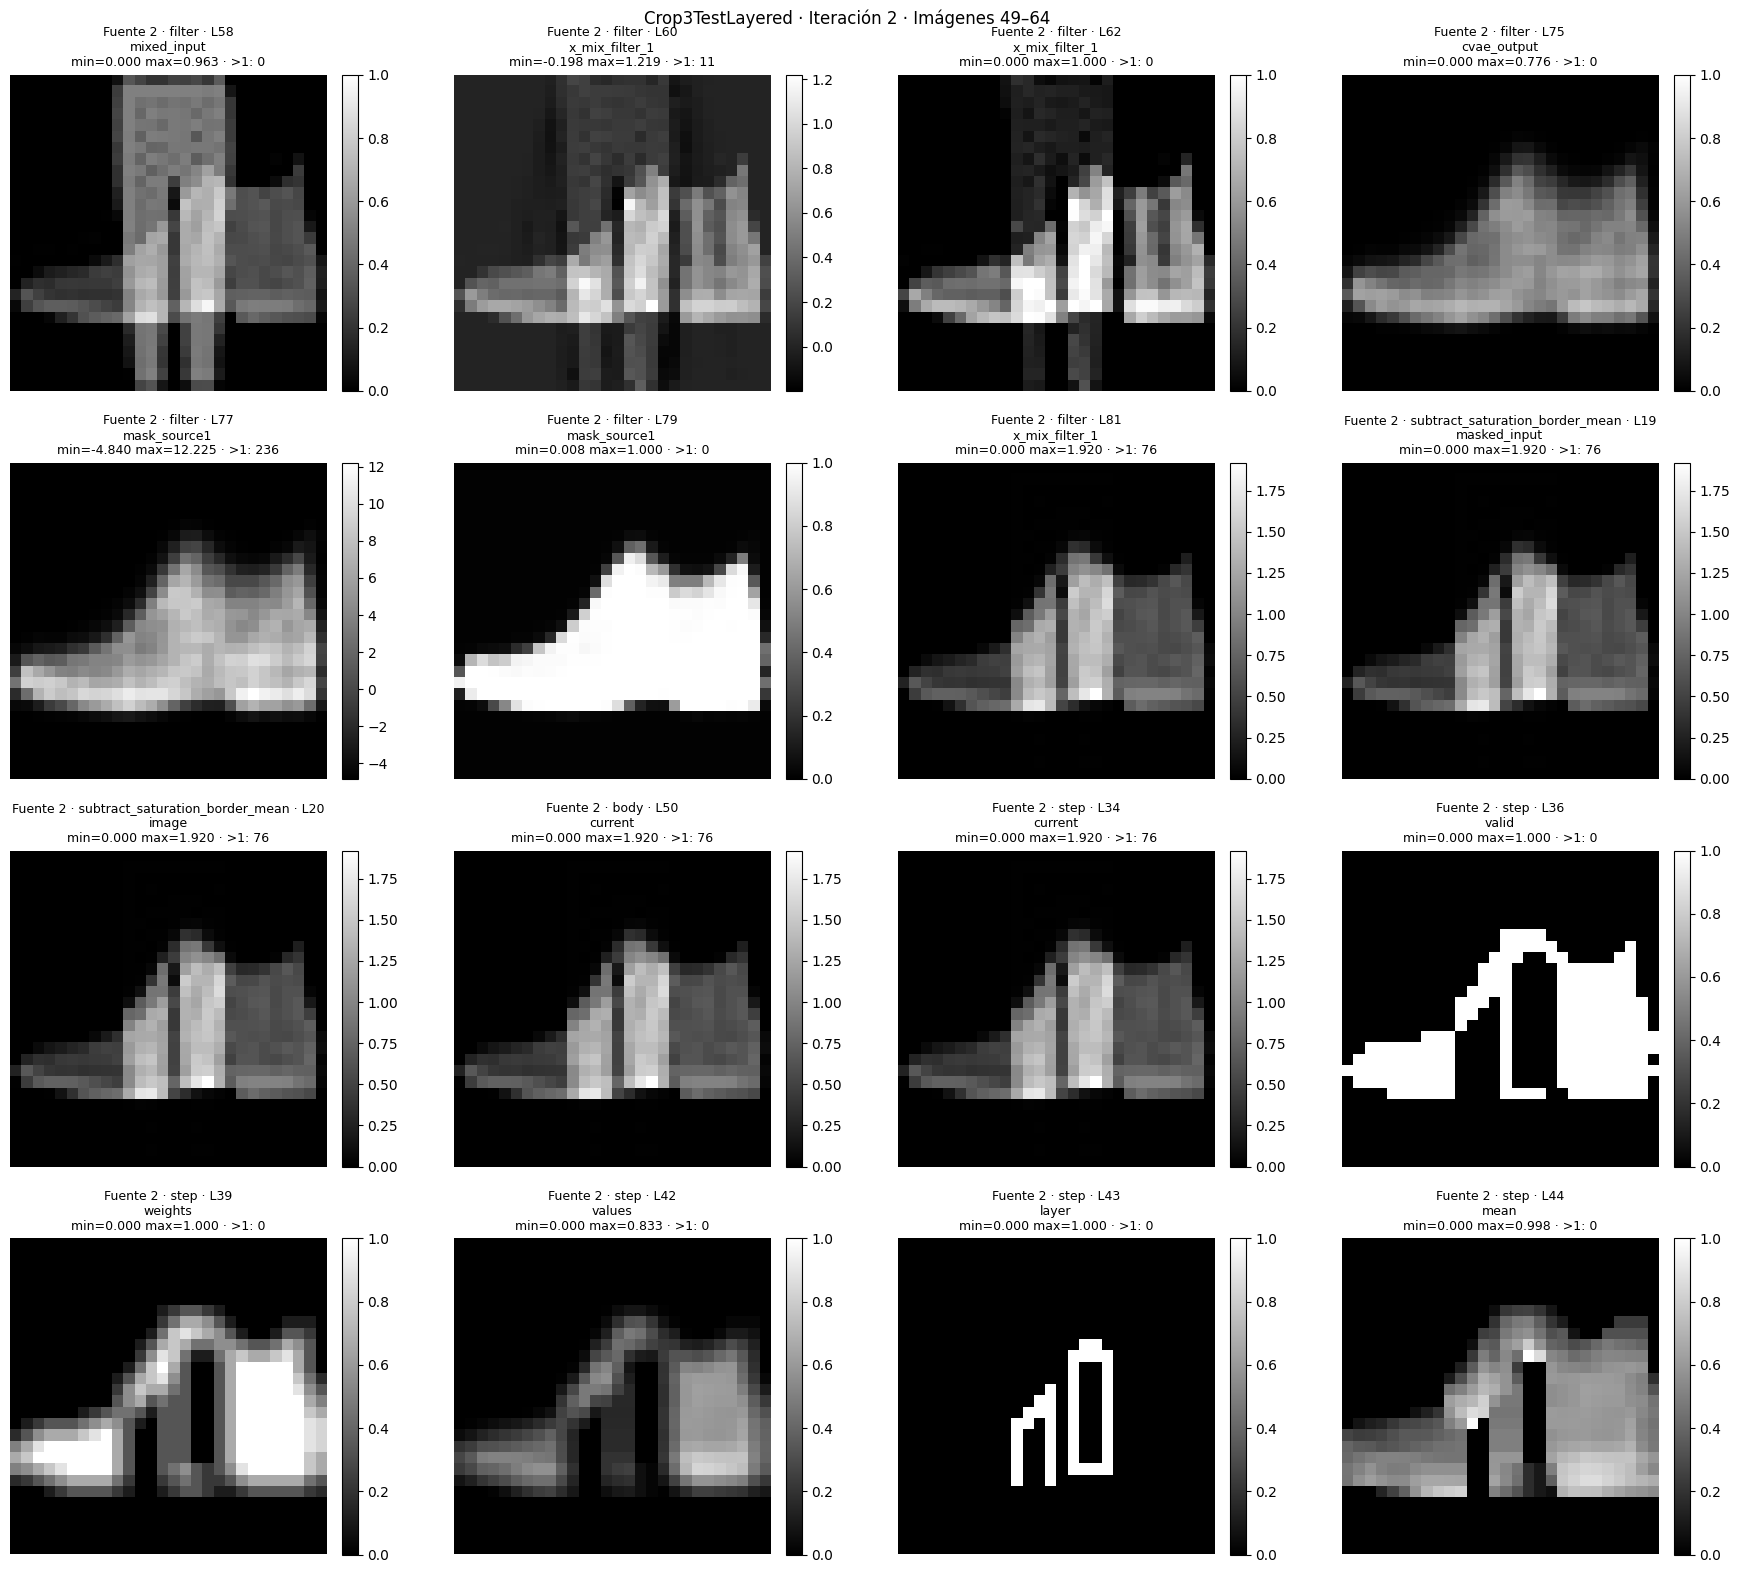

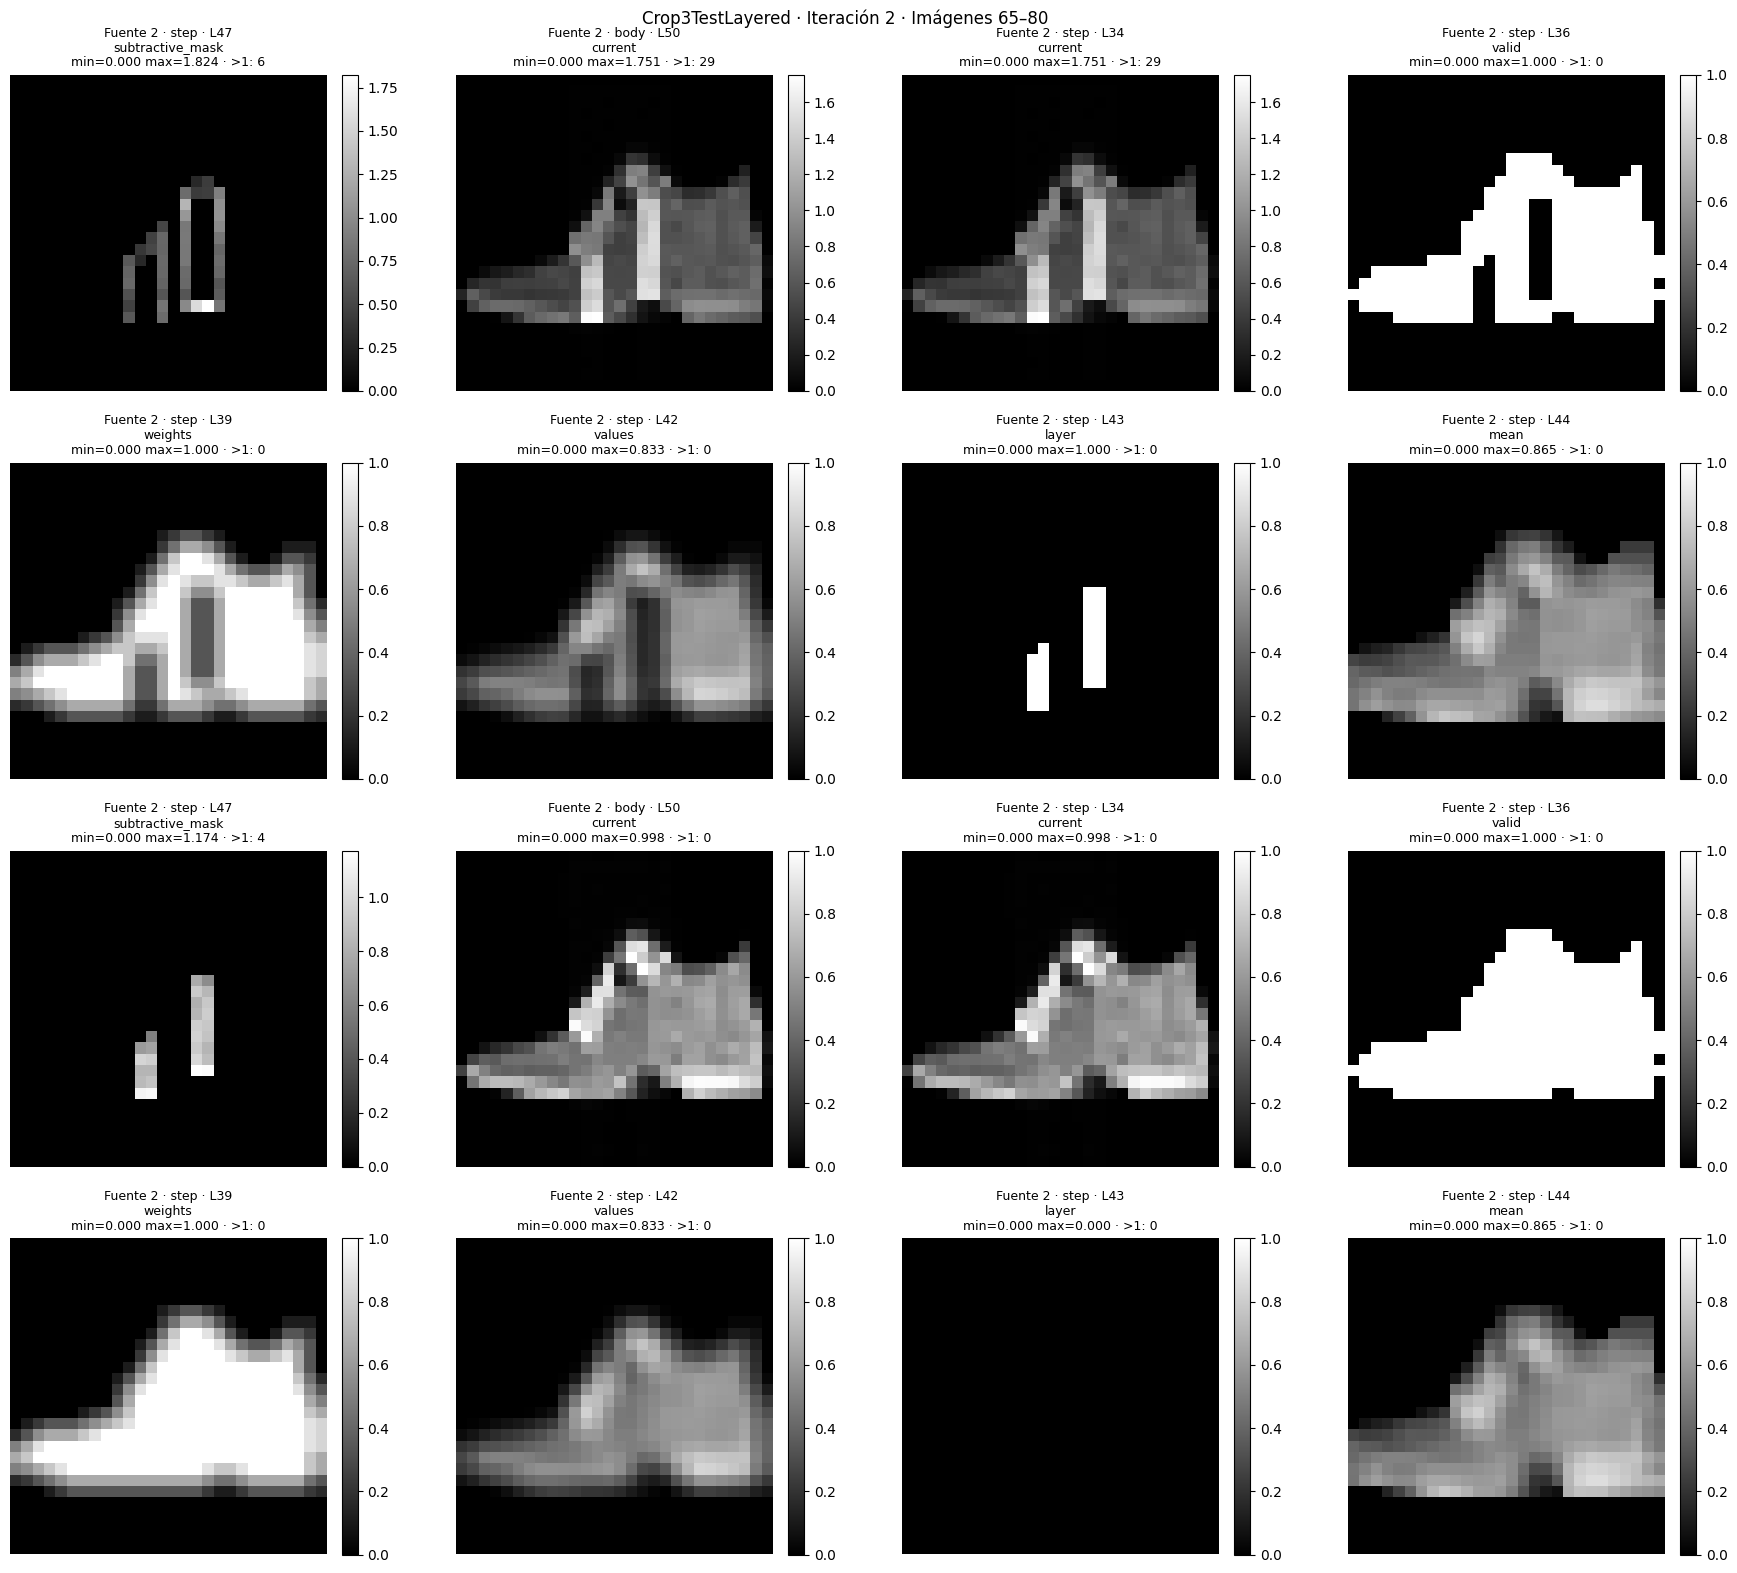

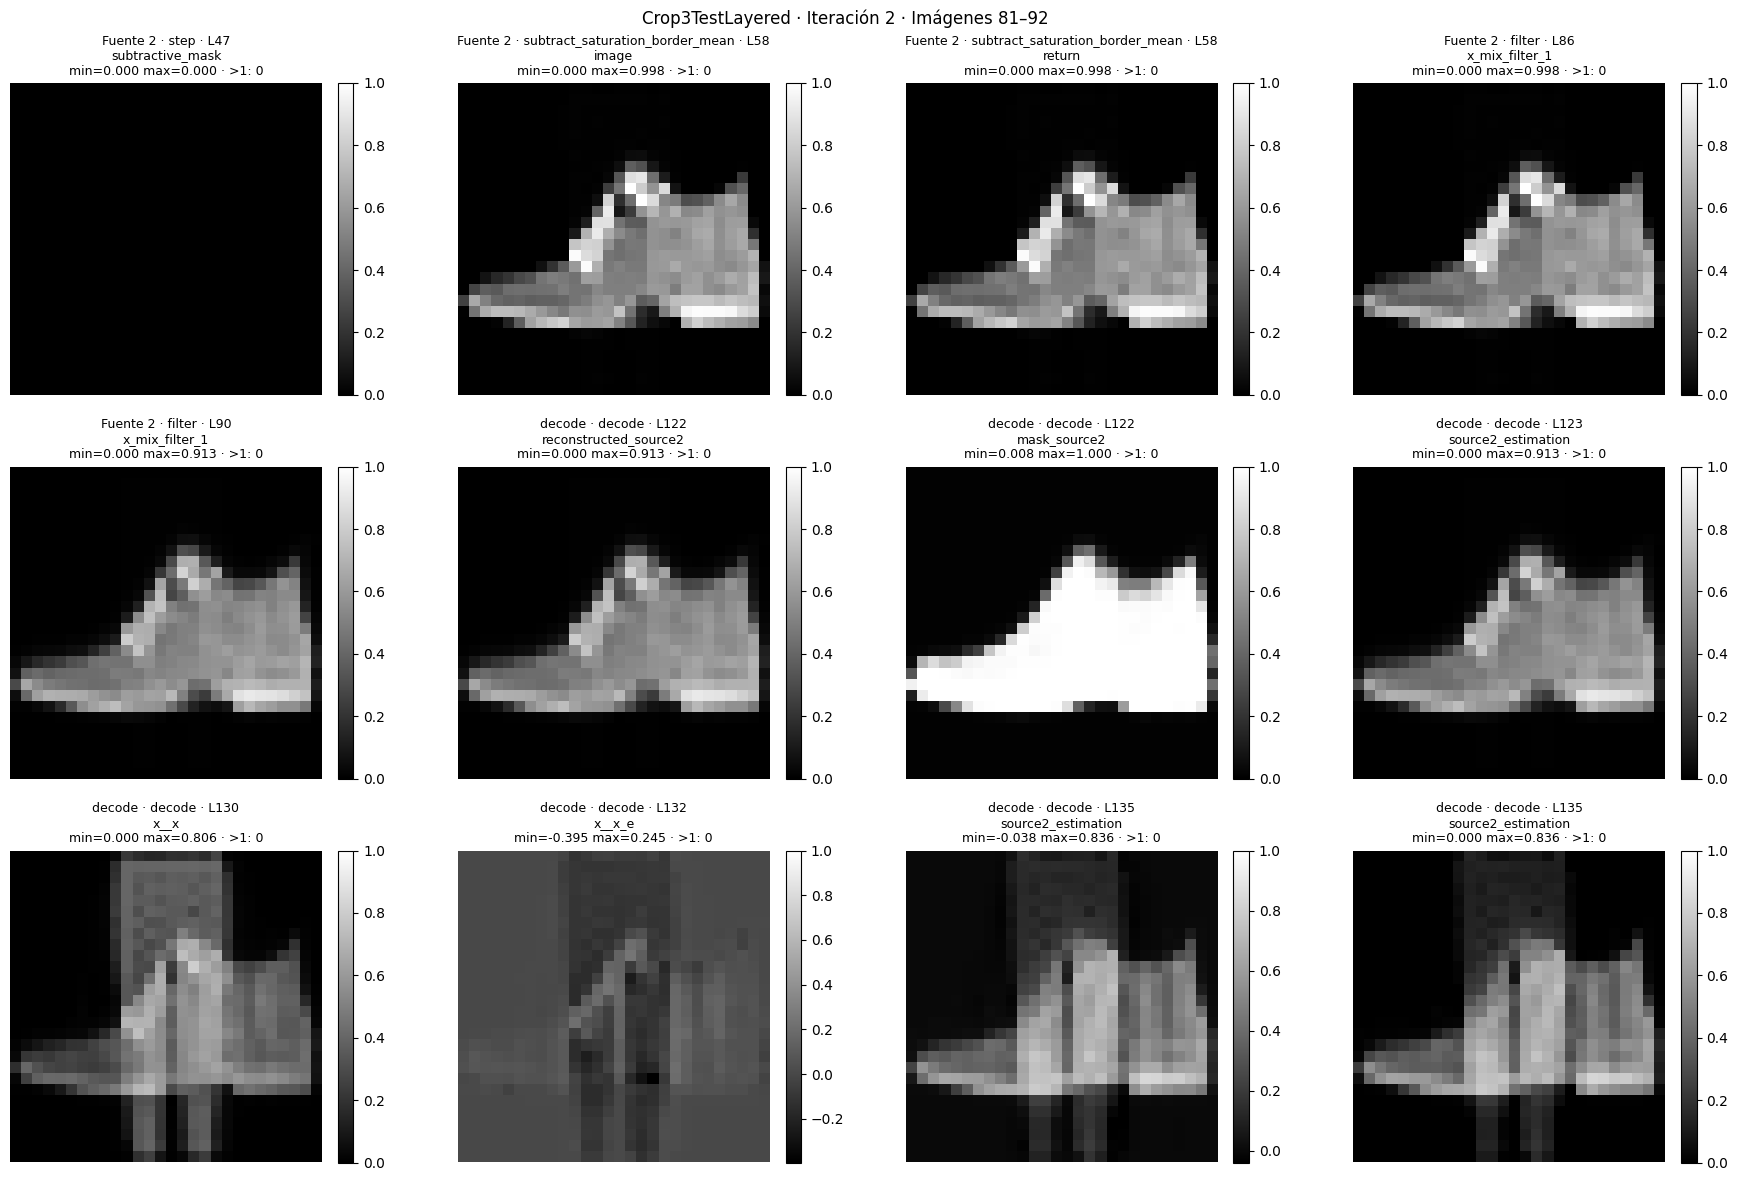

Iteración 3: 100 imágenes


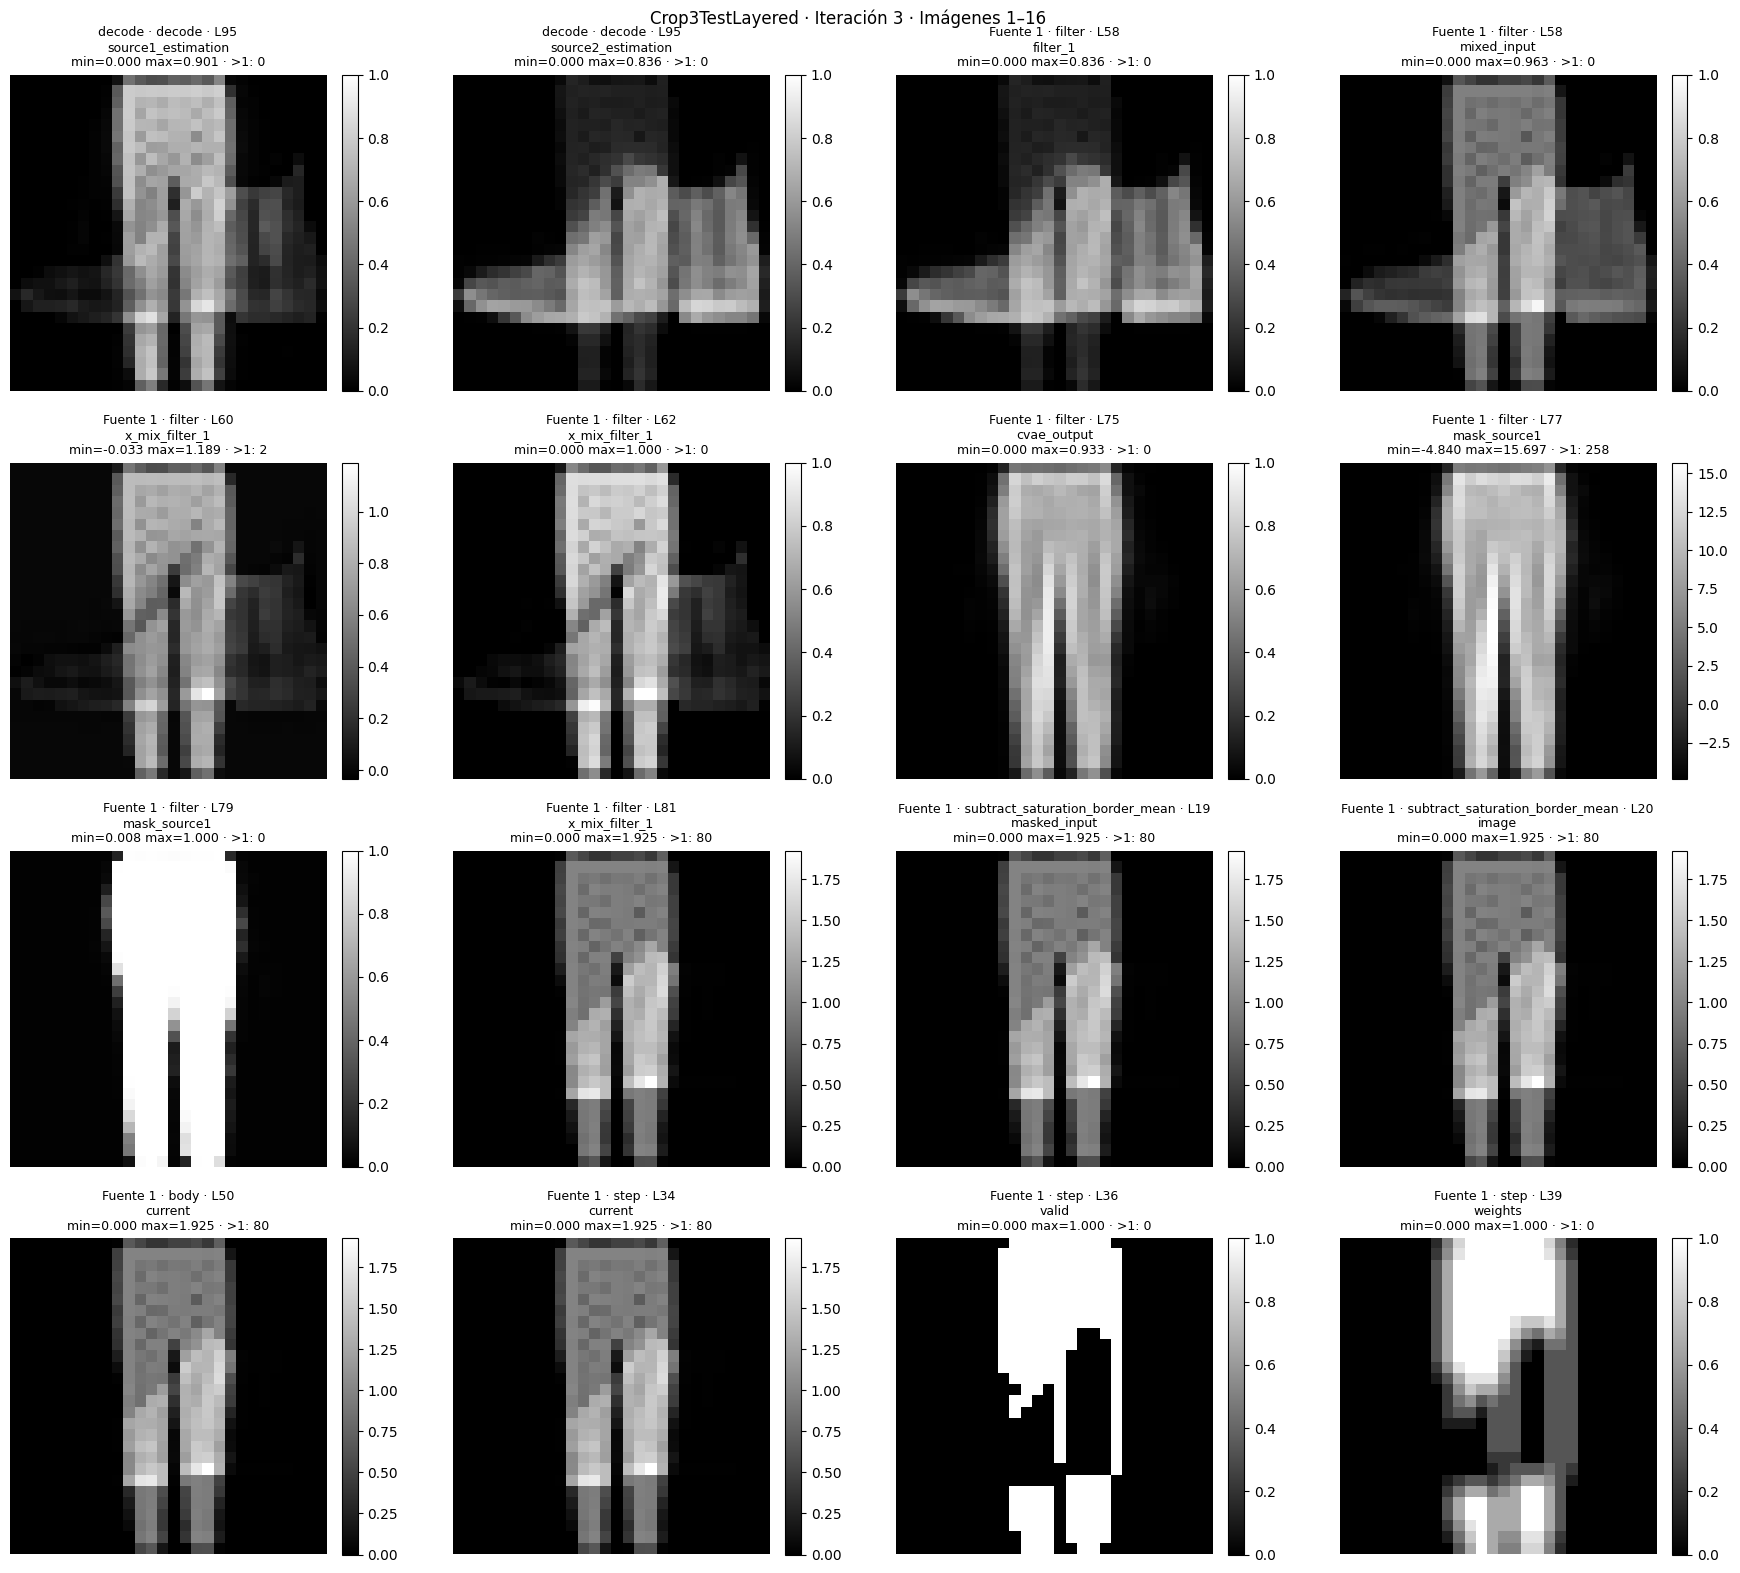

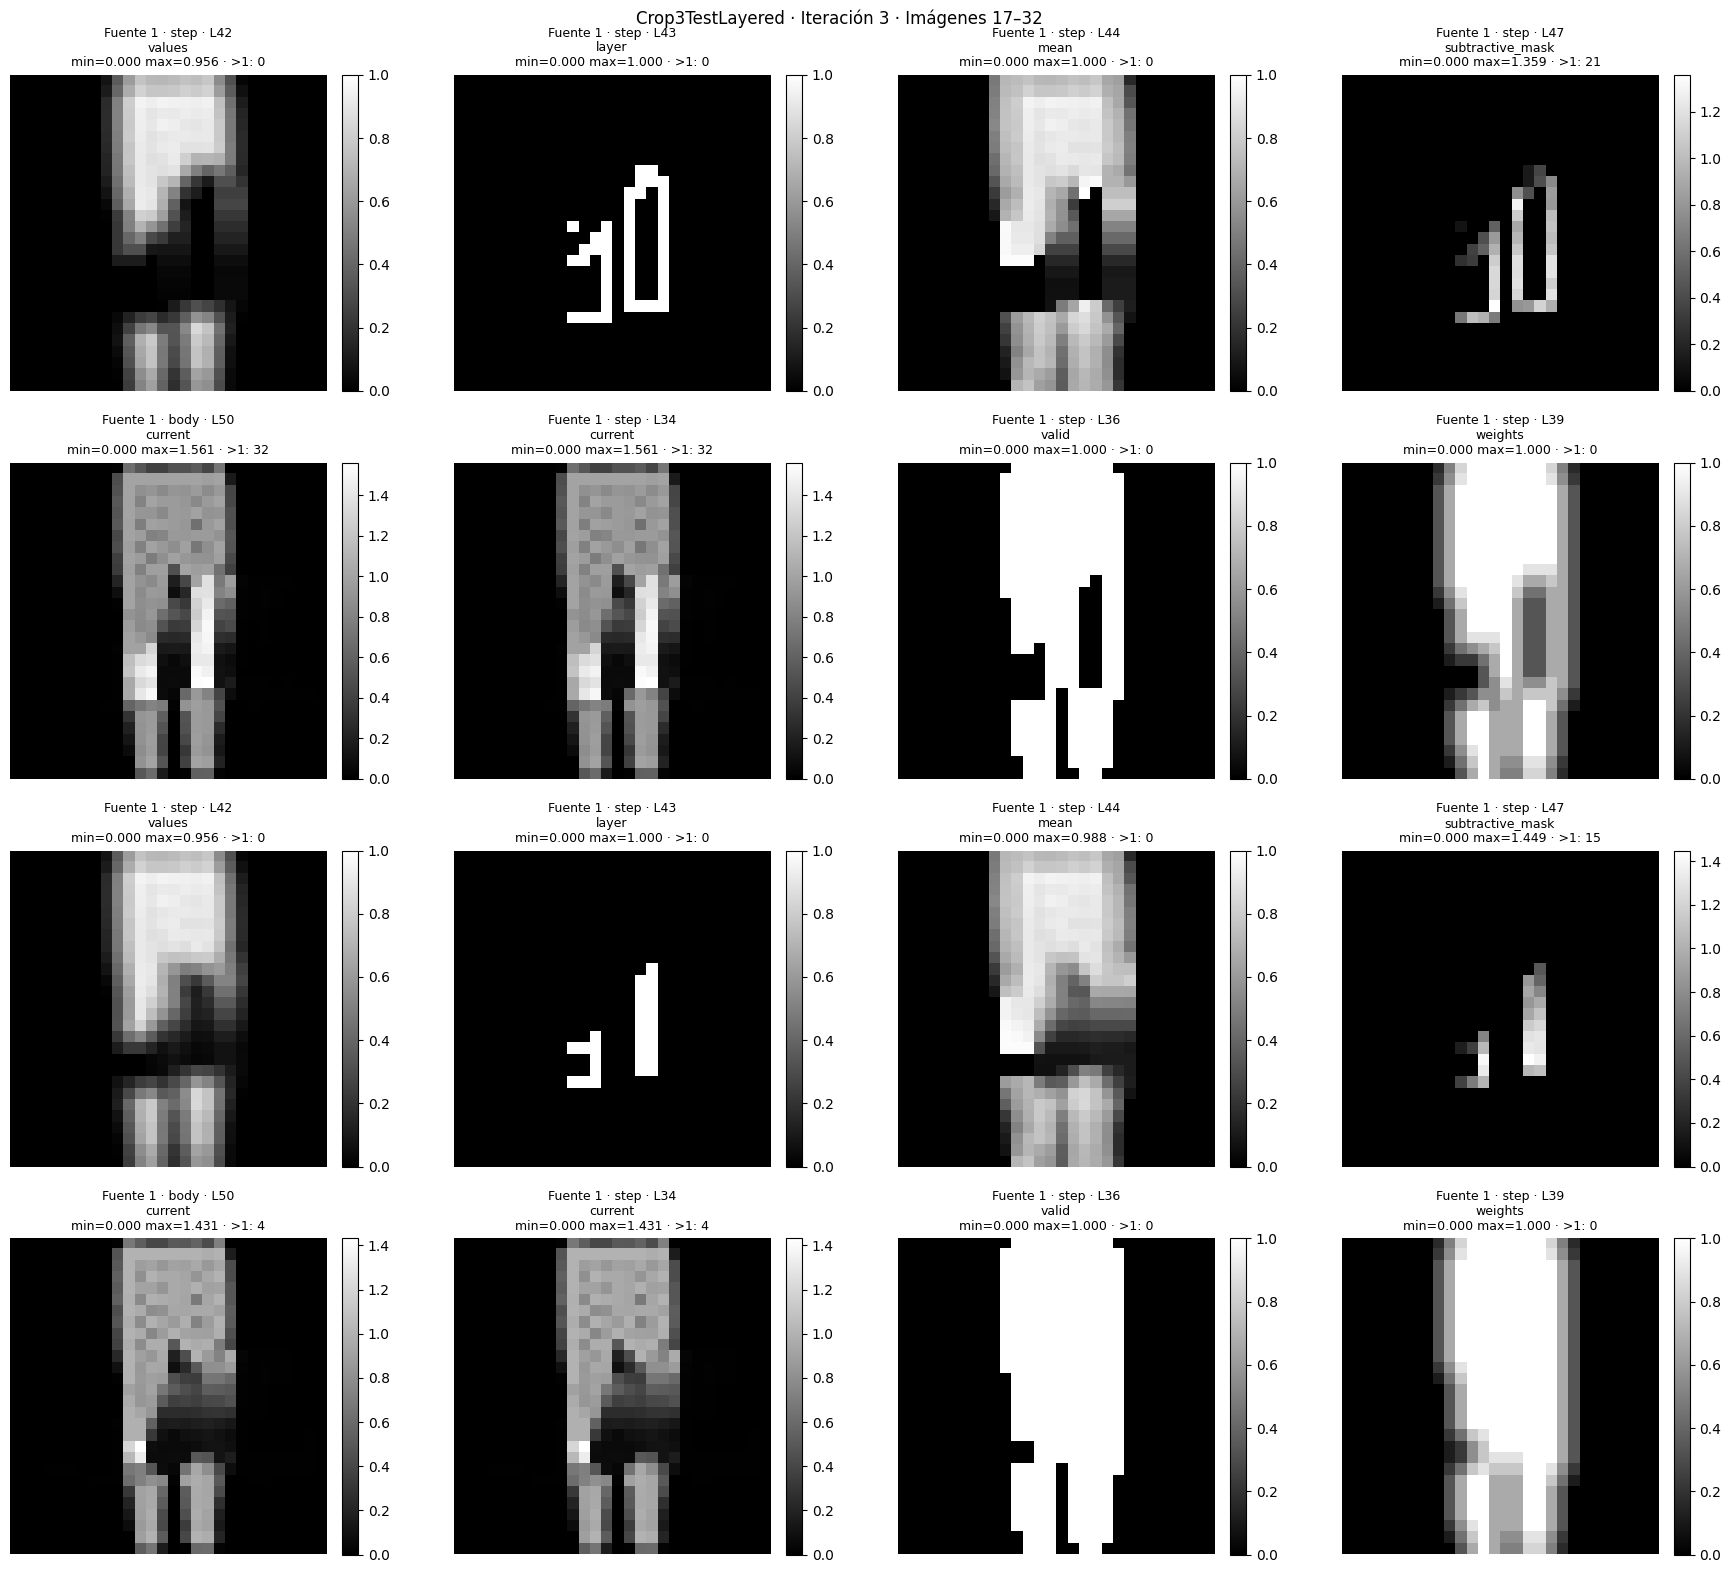

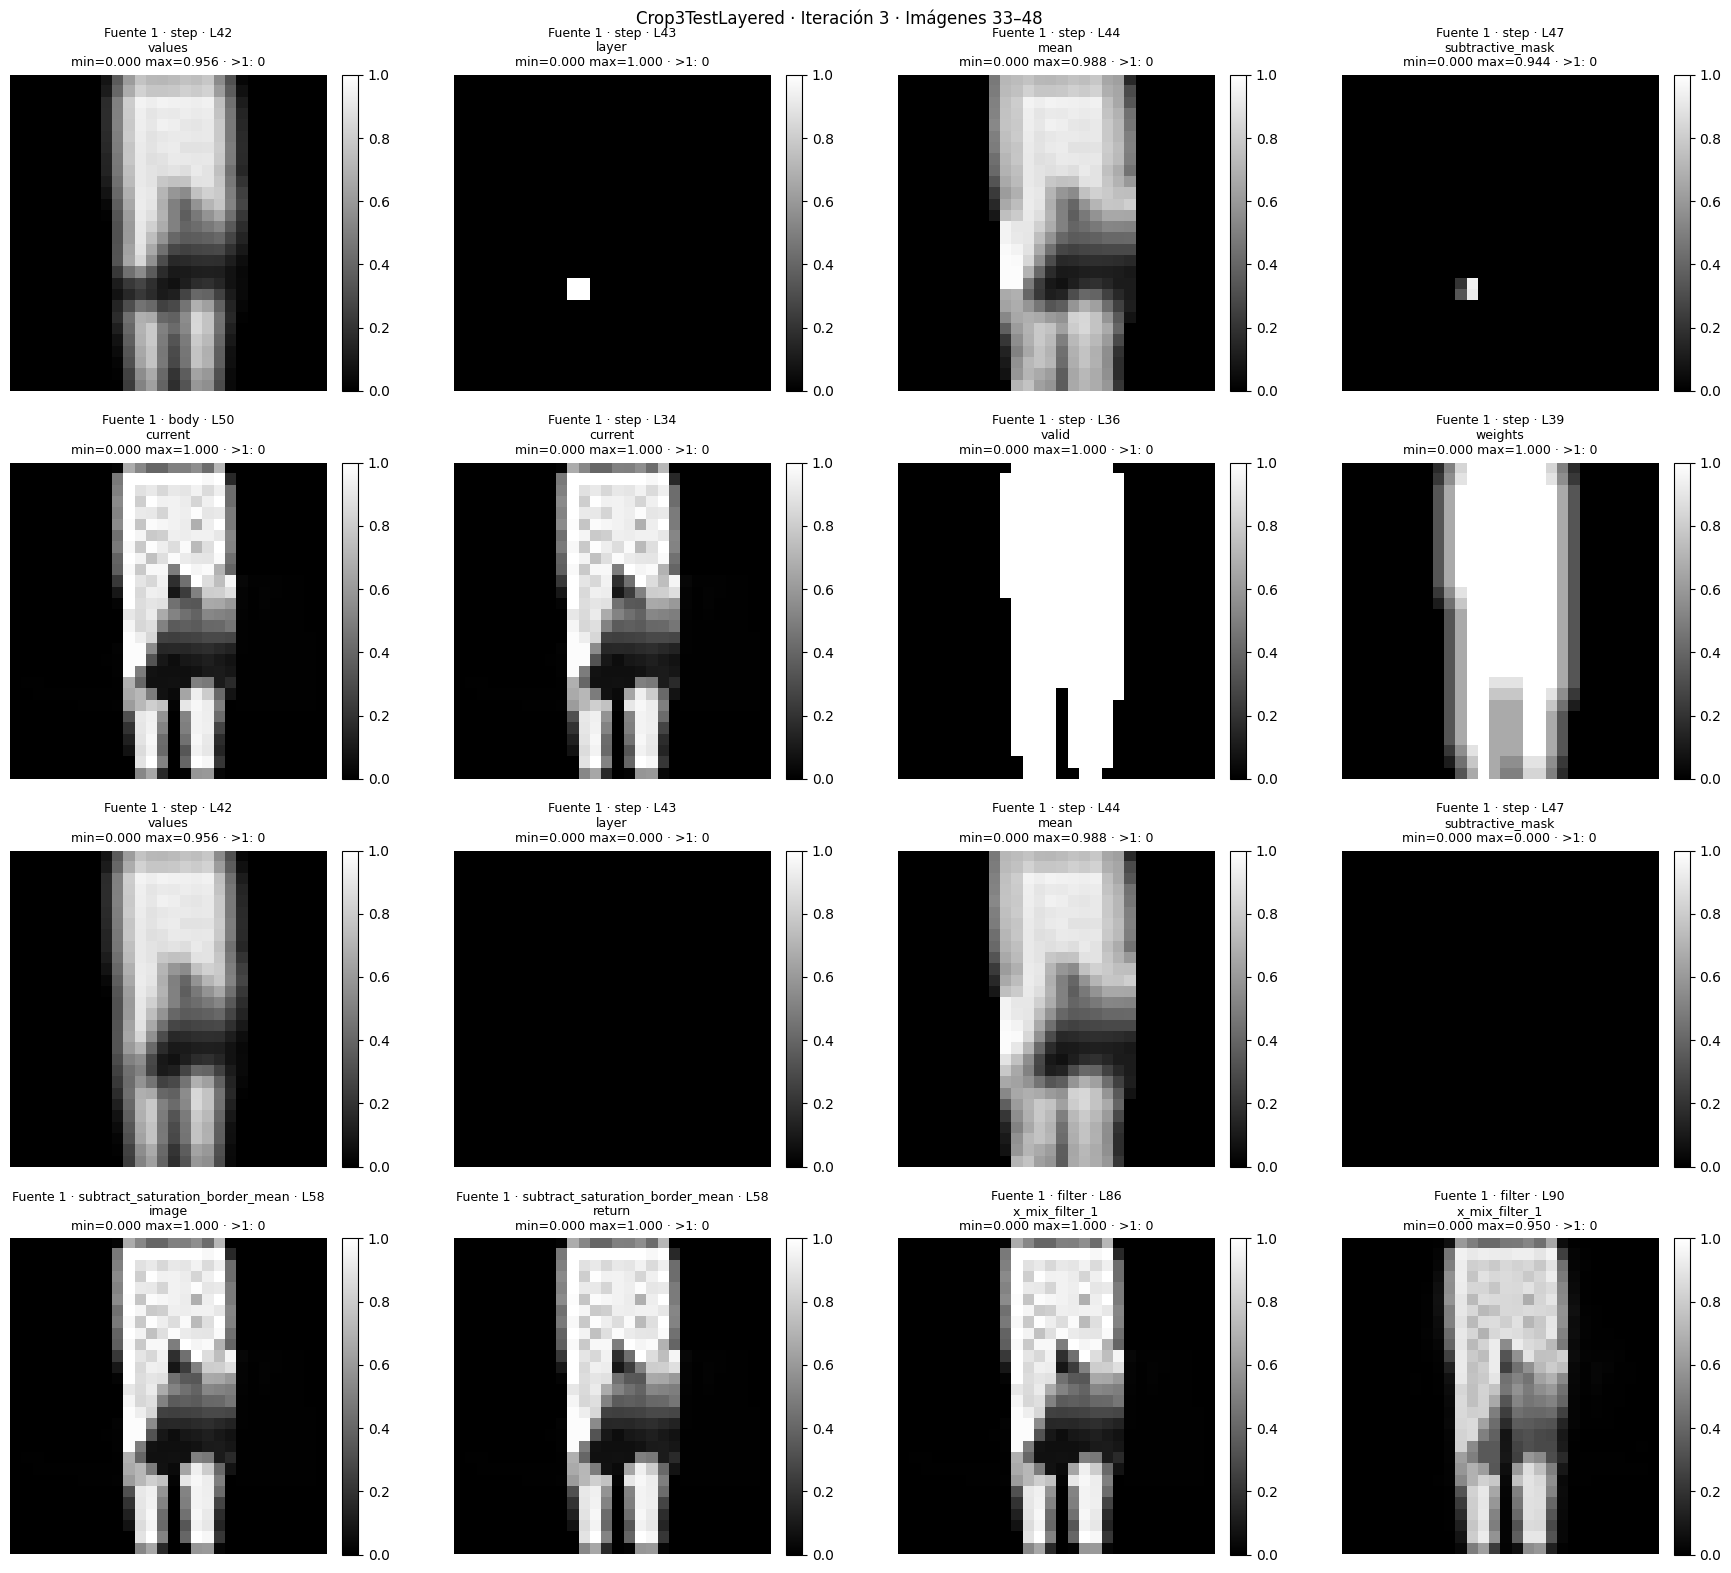

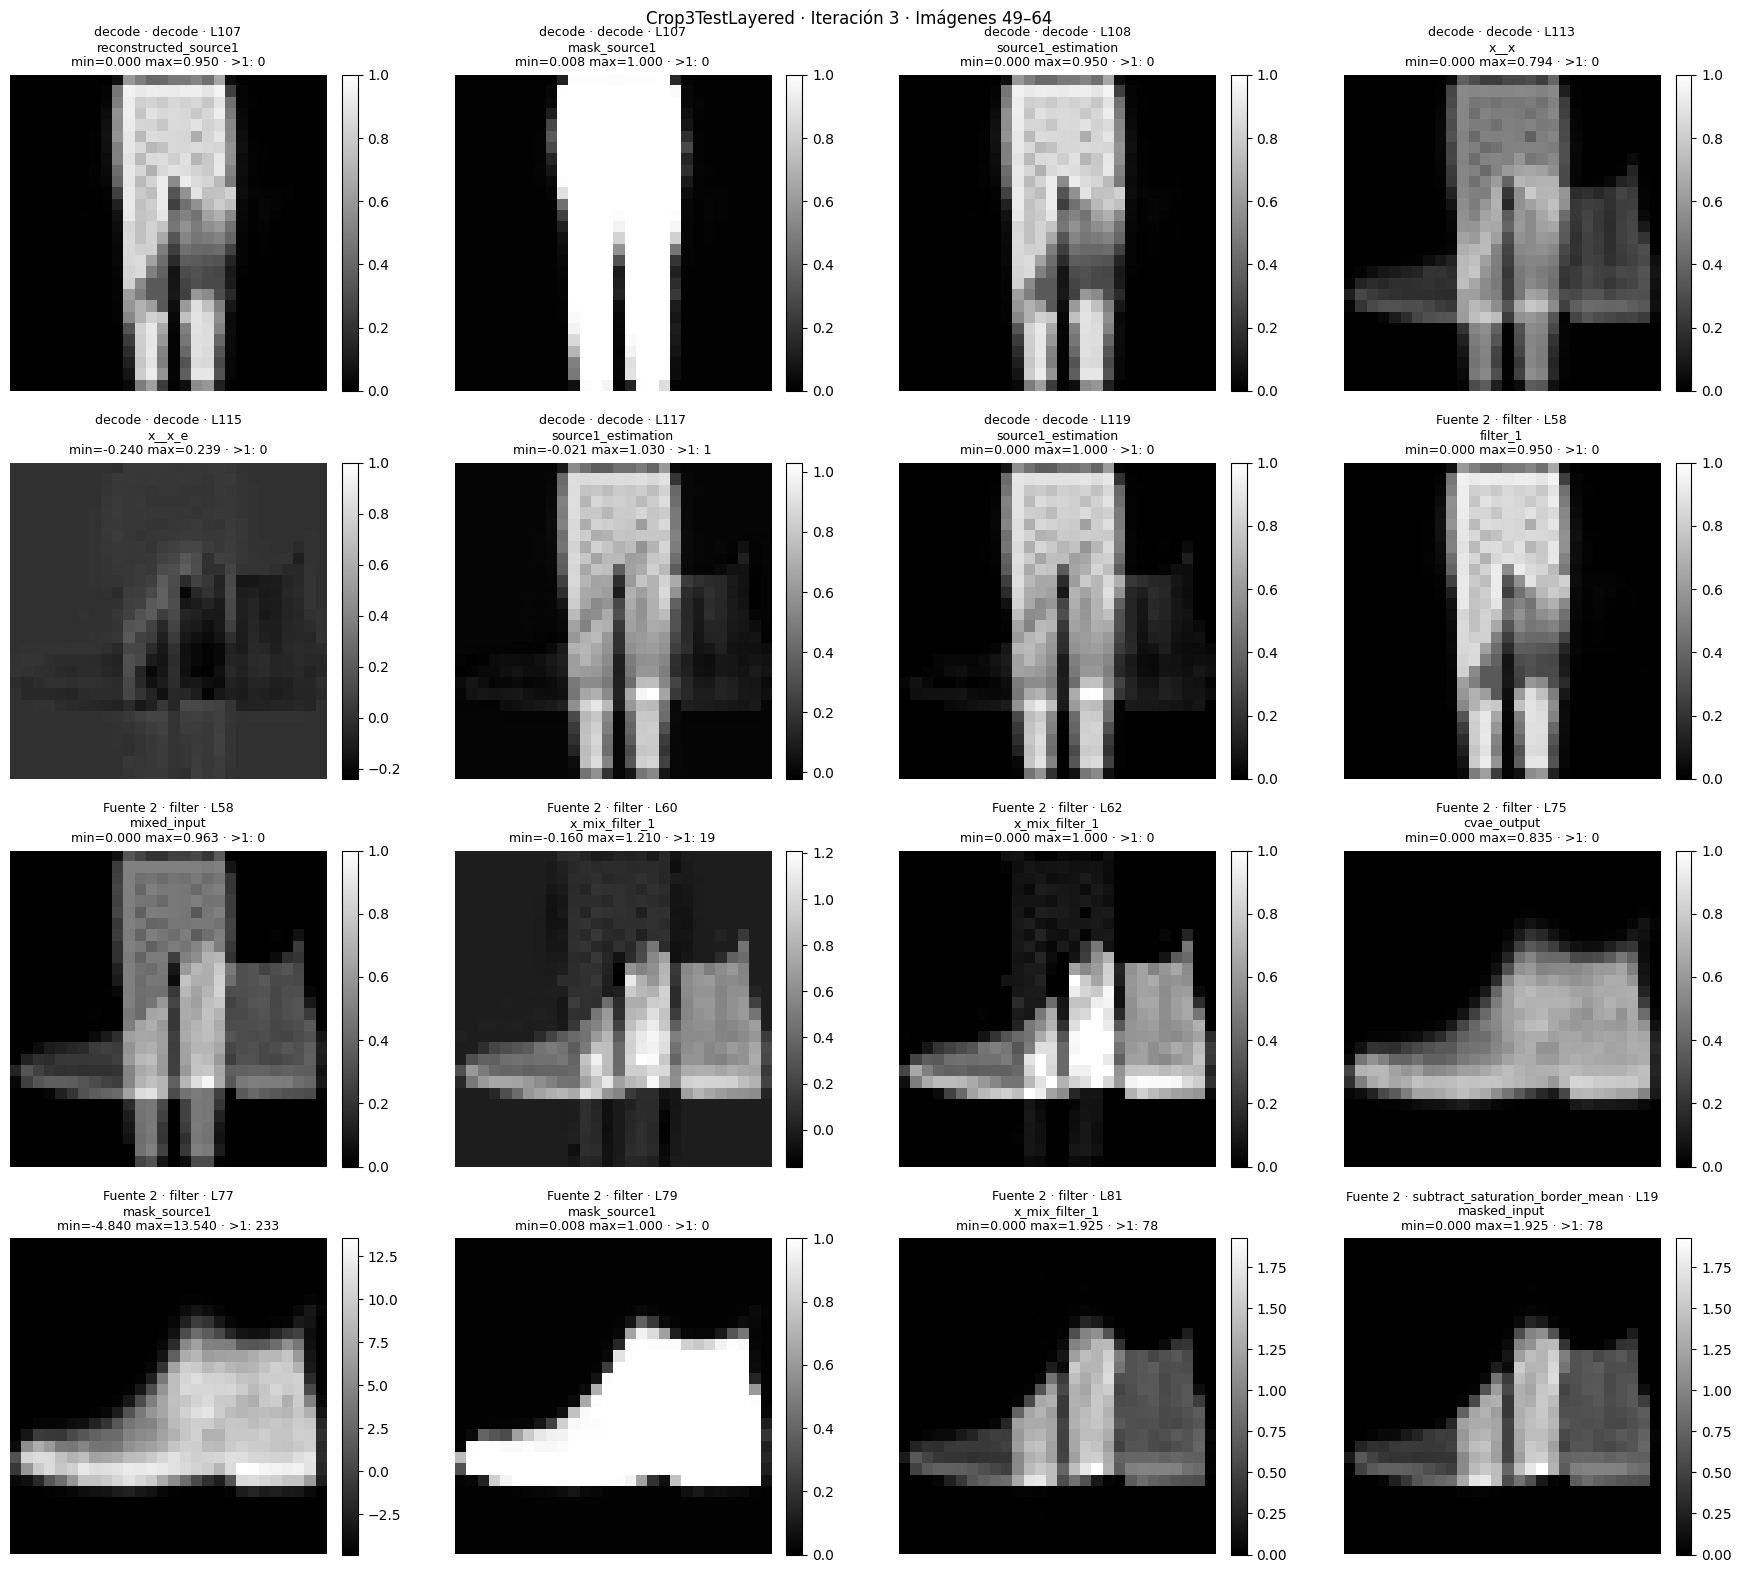

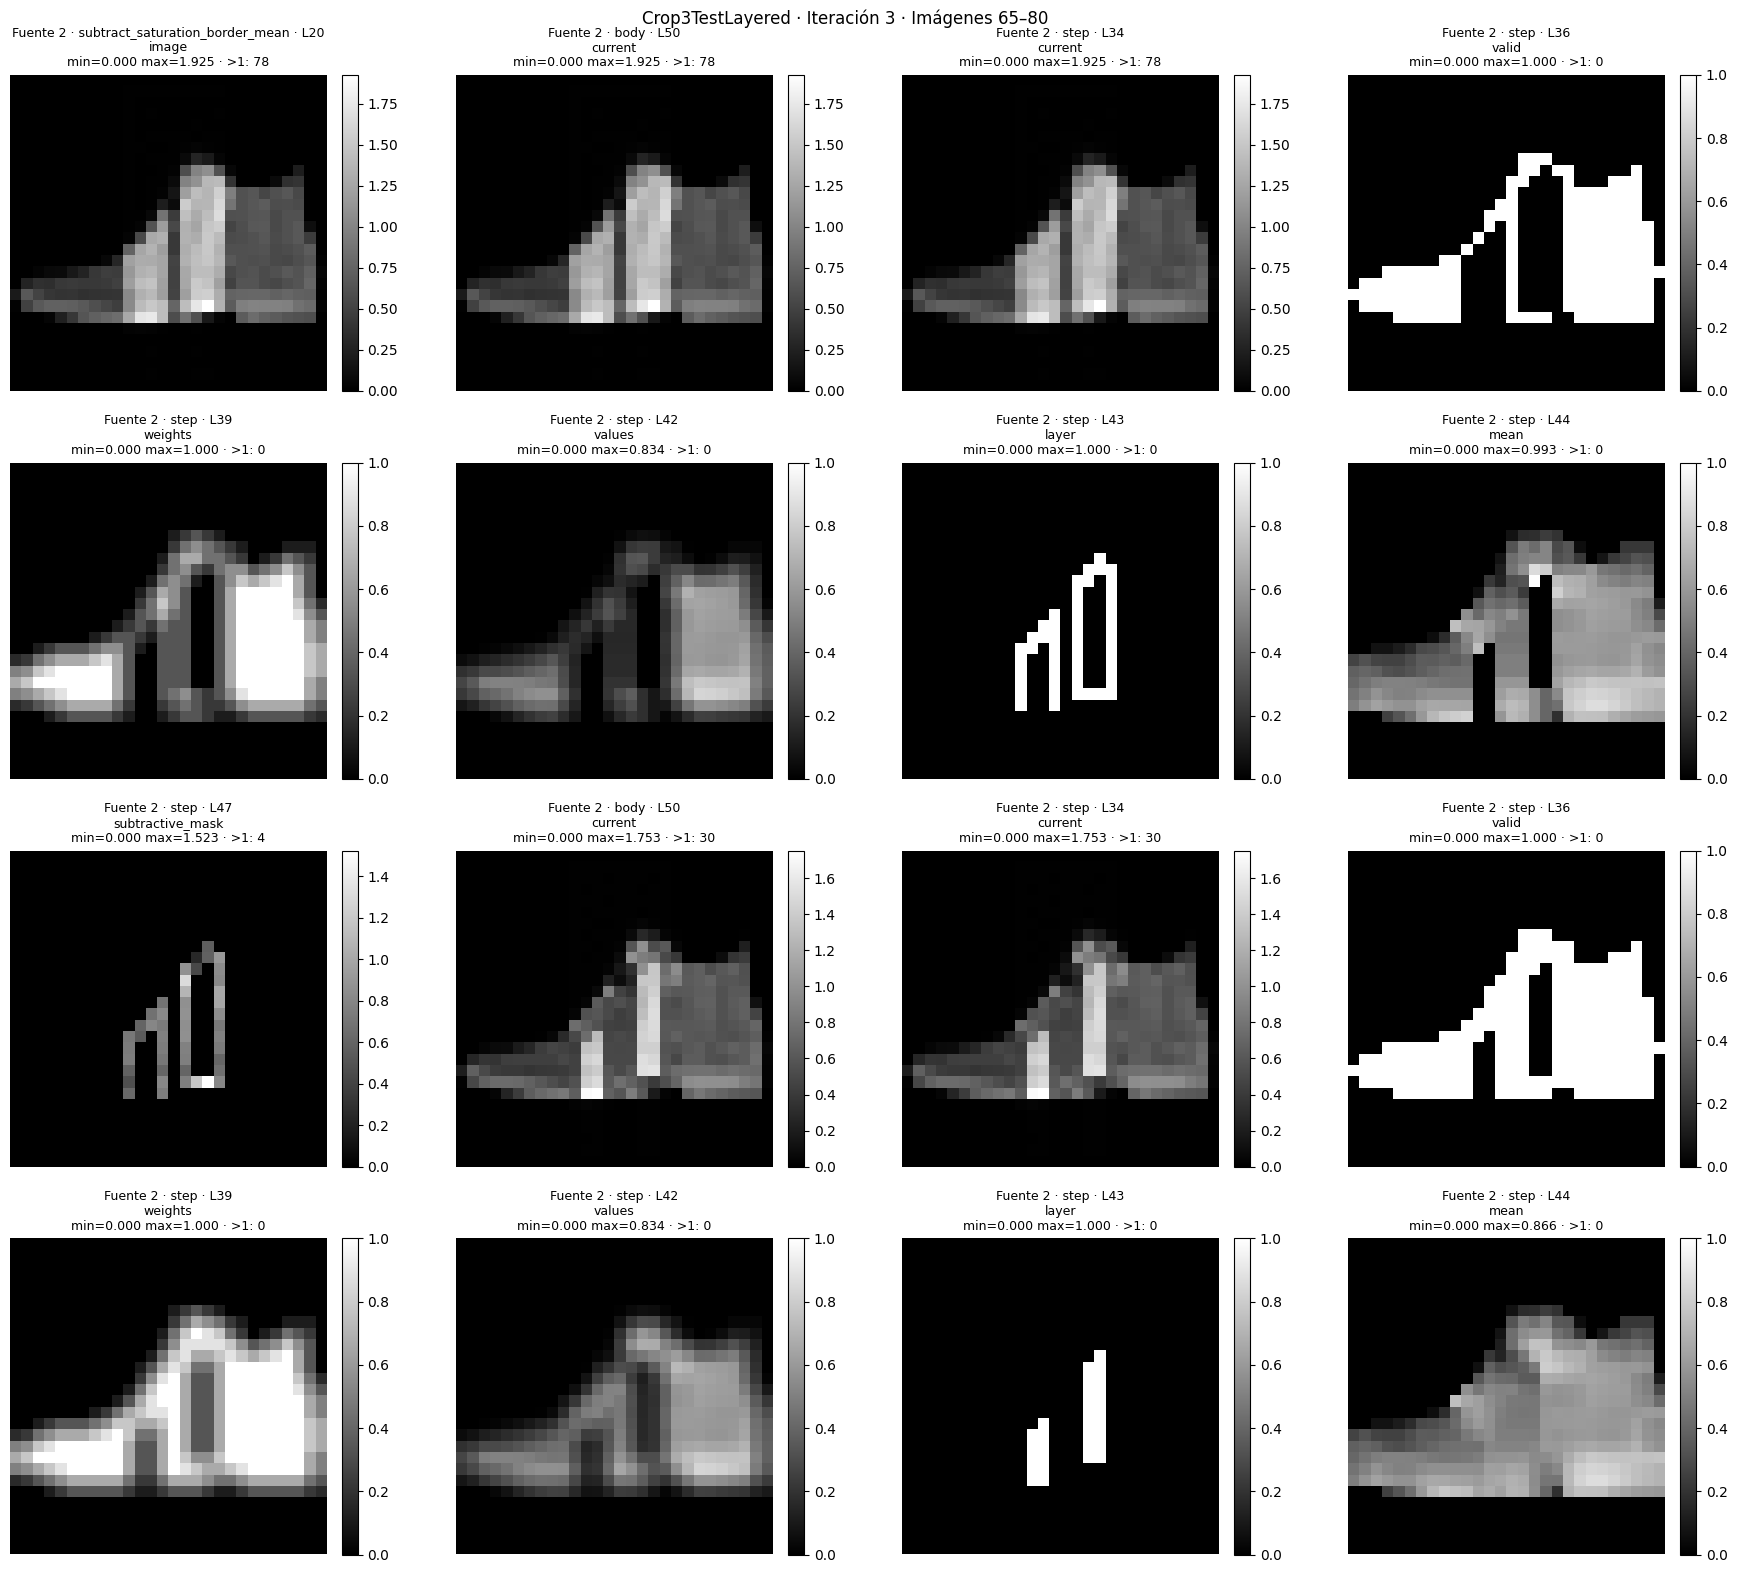

KeyboardInterrupt: 

In [5]:
# None muestra todas las iteraciones y ambas fuentes.
ONLY_ITERATION = None  # Ejemplo: 1 (numeración desde 1)
ONLY_SOURCE = None     # 1 o 2; decode siempre se incluye
COLUMNS = 4
IMAGES_PER_FIGURE = 16

records = [r for r in trace.records
           if (ONLY_ITERATION is None or r["iteration"] == ONLY_ITERATION)
           and (ONLY_SOURCE is None or r["source"] == ONLY_SOURCE
                or r["function"] == "decode")]

for iteration in sorted({r["iteration"] for r in records}):
    group = [r for r in records if r["iteration"] == iteration]
    print(f"Iteración {iteration}: {len(group)} imágenes")
    for start in range(0, len(group), IMAGES_PER_FIGURE):
        page = group[start:start + IMAGES_PER_FIGURE]
        rows = (len(page) + COLUMNS - 1) // COLUMNS
        fig, axes = plt.subplots(rows, COLUMNS, figsize=(4.5 * COLUMNS, 4 * rows), squeeze=False)
        for ax, record in zip(axes.flat, page):
            image = record["image"].astype(float)
            finite = image[np.isfinite(image)]
            low = min(0.0, finite.min()) if finite.size else 0.0
            high = max(1.0, finite.max()) if finite.size else 1.0
            plot = ax.imshow(image, cmap="gray", vmin=low, vmax=high)
            label = "decode" if record["function"] == "decode" else f"Fuente {record['source']}"
            ax.set_title(f"{label} · {record['function']} · L{record['line']}\n"
                         f"{record['variable']}\n"
                         f"min={image.min():.3f} max={image.max():.3f} · >1: {(image > 1).sum()}", fontsize=9)
            ax.axis("off")
            fig.colorbar(plot, ax=ax, fraction=0.046, pad=0.04)
        for ax in list(axes.flat)[len(page):]:
            ax.axis("off")
        fig.suptitle(f"{MODEL} · Iteración {iteration} · Imágenes {start + 1}–{start + len(page)}")
        fig.tight_layout()
        plt.show()
        plt.close(fig)


## Evolución de las dos estimaciones

Una fila por iteración externa, con la misma escala `[0, 1]`.

In [ ]:
for start in range(0, len(estimates), 10):
    page = estimates[start:start + 10]
    fig, axes = plt.subplots(len(page), 2, figsize=(7, 3 * len(page)), squeeze=False)
    for row, pair in enumerate(page):
        for column, image in enumerate(pair):
            axes[row, column].imshow(image, cmap="gray", vmin=0, vmax=1)
            axes[row, column].set_title(f"Iteración {start + row + 1} · Fuente {column + 1}")
            axes[row, column].axis("off")
    fig.tight_layout()
    plt.show()
    plt.close(fig)
